# Ripasso di Machine Learning: una mappa dei modelli

Foglio di appunti **condiviso**: lo leggiamo e lo completiamo insieme. Le celle intitolate **"Le tue parole"** sono per te: scrivi lì con parole tue, io correggo con garbo.

**Come è fatto.** Ogni modello ha una scheda con le stesse cinque voci:
1. **Idea** in una frase
2. **Peculiarità**: cosa lo distingue dagli altri
3. **Forte** e 4. **Debole**
5. **Manopole**: gli iperparametri che finiscono nella griglia del progetto

Tutti i classificatori sono provati **sugli stessi tre dataset giocattolo**, così vedi la differenza e non solo la descrizione.

**Fonti.** Le etichette `[corso]` indicano cose dette nei notebook del prof (01-09) o nelle slide. Le etichette `[mio]` sono aggiunte mie di conoscenza generale: confrontale con le slide prima di fidarti.

**Prerequisito.** Scala sempre le feature (`StandardScaler`) per i modelli che usano distanze o gradient descent: lo facciamo dentro una `Pipeline`.

**Aggiornamento.** Aggiunti: approfondimenti per ogni modello (sul modello delle tue note sulla SVM), multiclasse (nb 03), feature mapping (nb 04), Parte B completa con le slide *Dimensionality Reduction*, metriche e nested CV (nb 06), preprocessing (nb 01). Le tue celle non sono state modificate; dopo le tue note sulla SVM c'è una nota del tutor.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.base import clone, BaseEstimator, ClassifierMixin
from sklearn.datasets import make_blobs, make_moons, make_circles, load_digits
from sklearn.model_selection import train_test_split, cross_val_score, validation_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import Perceptron, LogisticRegression, LinearRegression, Ridge, RidgeCV
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.decomposition import PCA, KernelPCA
from sklearn.dummy import DummyClassifier
from sklearn.metrics import mean_squared_error

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .25})
CMAP = plt.cm.coolwarm

## 0. I tre dataset giocattolo

Servono per vedere **che forma di confine** sa disegnare ciascun modello.

- **separabile**: due nuvole divisibili da una retta
- **lune**: due mezzelune intrecciate, serve un confine curvo
- **cerchi**: una classe dentro l'altra, nessuna retta può funzionare

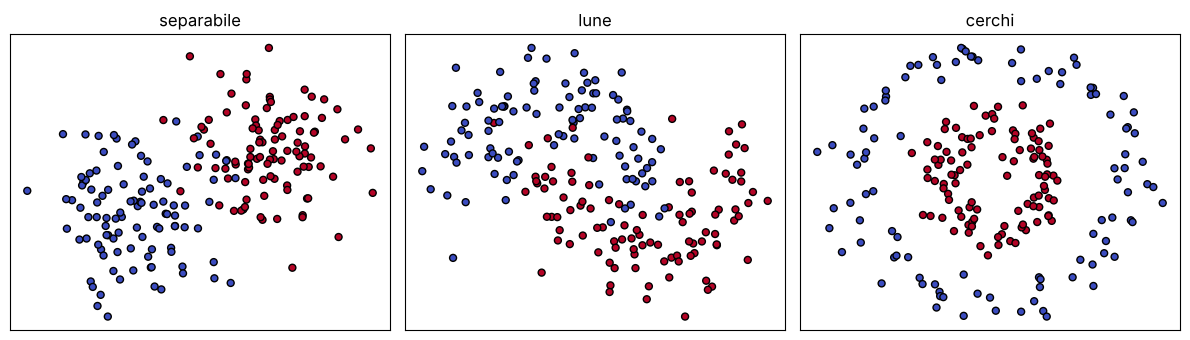

In [2]:
def crea_dati():
    X1, y1 = make_blobs(n_samples=200, centers=[[-2, -1], [2, 1]], cluster_std=1.2, random_state=0)
    X2, y2 = make_moons(200, noise=0.25, random_state=0)
    X3, y3 = make_circles(200, noise=0.1, factor=0.4, random_state=0)
    dati = {"separabile": (X1, y1), "lune": (X2, y2), "cerchi": (X3, y3)}
    split = {k: train_test_split(X, y, test_size=0.3, stratify=y, random_state=0) for k, (X, y) in dati.items()}
    return dati, split

DATI, SPLIT = crea_dati()

def disegna(ax, modello, nome, titolo=""):
    Xtr, Xte, ytr, yte = SPLIT[nome]
    mod = clone(modello).fit(Xtr, ytr)
    X = DATI[nome][0]
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - .7, X[:, 0].max() + .7, 250),
                         np.linspace(X[:, 1].min() - .7, X[:, 1].max() + .7, 250))
    Z = mod.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=.25, cmap=CMAP, levels=[-.5, .5, 1.5])
    ax.scatter(*Xtr.T, c=ytr, cmap=CMAP, edgecolor="k", s=25, label="train")
    ax.scatter(*Xte.T, c=yte, cmap=CMAP, edgecolor="k", s=70, marker="s", label="test")
    acc = mod.score(Xte, yte)
    ax.set_title(f"{titolo} {nome}: acc test = {acc:.2f}", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
    return mod, acc

def scheda_grafica(modello, titolo=""):
    fig, axs = plt.subplots(1, 3, figsize=(14, 4))
    for ax, nome in zip(axs, DATI):
        disegna(ax, modello, nome, titolo)
    axs[0].legend(loc="lower left", fontsize=8)
    plt.tight_layout(); plt.show()

fig, axs = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, (nome, (X, y)) in zip(axs, DATI.items()):
    ax.scatter(*X.T, c=y, cmap=CMAP, edgecolor="k", s=25); ax.set_title(nome); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

In [3]:
# Helper per scrivere note sopra i grafici (usato negli approfondimenti)
def annota(ax, testo, xy, xytext, colore="k"):
    ax.annotate(testo, xy=xy, xytext=xytext, fontsize=9, color=colore,
                arrowprops=dict(arrowstyle="->", color=colore, lw=1),
                bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=colore, alpha=.9))

# Parte A. Classificazione

Il filo conduttore, in una riga: **tutti questi modelli calcolano un punteggio e poi decidono la classe**. Cambia *come* scelgono i pesi e *che forma* può avere il confine.

Prima di tutto la baseline(il dummy), che non è un modello da vincere ma un **metro**.

## A0. Dummy classifier `[corso]`

- **Idea**: ignora completamente le feature e predice sempre la classe più frequente.
- **Peculiarità**: non impara niente. Serve da riferimento minimo: se il tuo modello non lo batte, non ha imparato nulla.
- **Forte**: costa zero, ti dice quanto vale "tirare a indovinare" con quelle proporzioni di classi.
- **Debole**: non è un candidato, è solo il metro. Con classi sbilanciate può avere accuracy alta (es. 95%) senza servire a niente.

In [4]:
for nome, (X, y) in DATI.items():
    Xtr, Xte, ytr, yte = SPLIT[nome]
    d = DummyClassifier(strategy="most_frequent").fit(Xtr, ytr)
    print(f"{nome:11s} dummy acc test = {d.score(Xte, yte):.2f}   (classi bilanciate: ci aspettiamo circa 0.5)")

separabile  dummy acc test = 0.50   (classi bilanciate: ci aspettiamo circa 0.5)
lune        dummy acc test = 0.50   (classi bilanciate: ci aspettiamo circa 0.5)
cerchi      dummy acc test = 0.50   (classi bilanciate: ci aspettiamo circa 0.5)


## A1. Perceptron `[corso]`

- **Idea**: calcola $z = \mathbf{w}^\top \mathbf{x}$ e usa una **soglia**: classe +1 se $z\ge 0$, altrimenti −1. Ad ogni errore sposta i pesi verso il punto sbagliato.
- **Peculiarità**: l'errore è **0 o 1** (giusto/sbagliato), non dice "di quanto" sbagli. Nessuna probabilità.
- **Forte**: semplicissimo e veloce. Se i dati sono linearmente separabili, **converge** a una retta che li separa tutti `[corso]`.
- **Debole**: se i dati **non** sono separabili non si stabilizza mai: i pesi continuano a oscillare `[corso]`. Tra le infinite rette corrette ne prende una qualunque, non la migliore `[mio]`.
- **Manopole**: `eta0` (learning rate), `max_iter`.

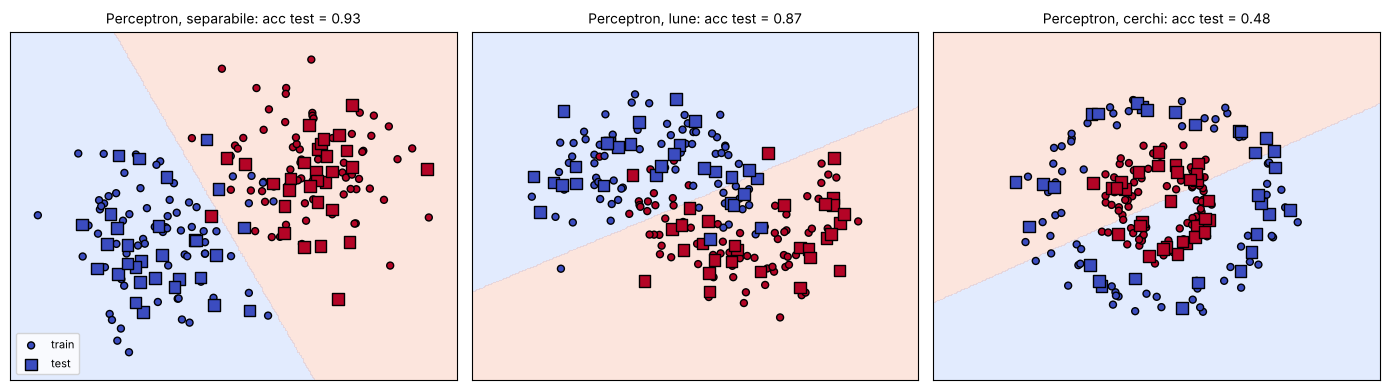

In [5]:
scheda_grafica(make_pipeline(StandardScaler(), Perceptron(random_state=0)), "Perceptron,")

### Approfondimento: Perceptron

**Perché si chiama così?** Viene dal neurone artificiale di McCulloch-Pitts (nb 02): riceve gli input $x_j$, li pesa con $w_j$, li somma in $z=\mathbf{w}^\top\mathbf{x}$ e "si accende" (+1) se la somma supera la soglia. *Perceptron* = la macchina che "percepisce" e decide.

**Come impara, con i numeri.** La regola di aggiornamento è
$$w_j \leftarrow w_j + \eta\,(y - \hat y)\,x_j$$
- $y$ = classe vera, $\hat y$ = classe predetta, $\eta$ = learning rate.
- Se la predizione è giusta, $y-\hat y=0$: **i pesi non cambiano**.
- Se è sbagliata, $y-\hat y=\pm2$: i pesi si spostano verso il punto sbagliato.

Esempio: $\mathbf{w}=(0.2,\,-0.5)$, punto $\mathbf{x}=(1,\,1)$ con classe vera $y=+1$, $\eta=0.1$.
1. $z = 0.2\cdot1 - 0.5\cdot1 = -0.3 < 0$, quindi $\hat y=-1$: **sbagliato**.
2. $\Delta\mathbf{w} = 0.1\cdot(1-(-1))\cdot(1,1) = (0.2,\,0.2)$.
3. Nuovi pesi $\mathbf{w}=(0.4,\,-0.3)$: ora $z=0.1\ge0$, quindi $\hat y=+1$. **Corretto.**

**Il punto chiave** (nb 02, *Algorithm convergence*): se le classi sono separabili da una retta, il numero di errori arriva a 0 e si ferma. Se non lo sono, c'è sempre un punto sbagliato, quindi i pesi non smettono mai di cambiare. Il grafico sotto lo mostra.

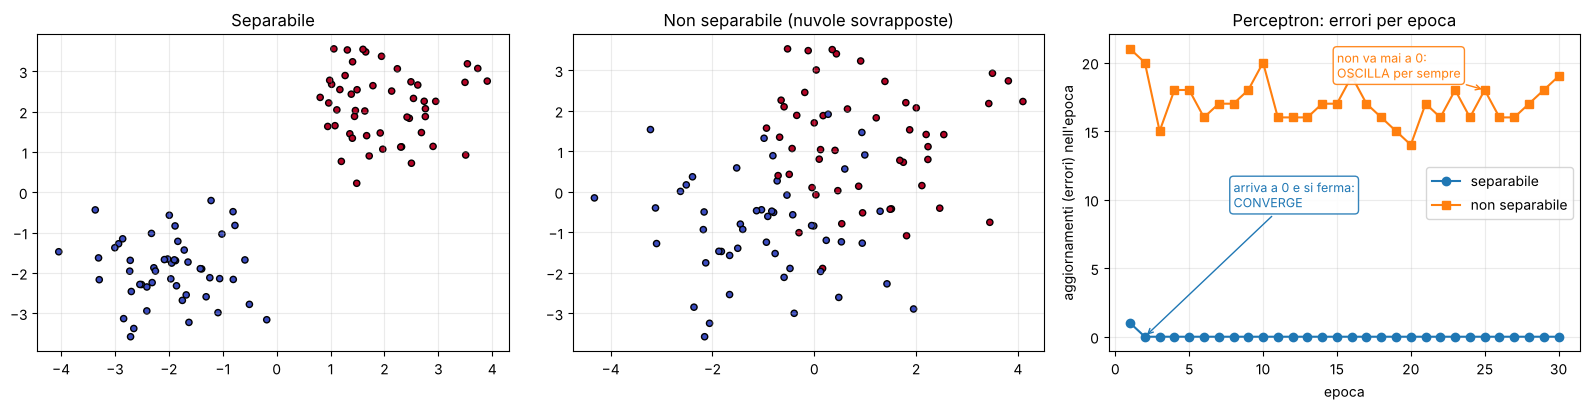

In [6]:
def perceptron_errori(X, y, eta=0.1, epoche=30, seed=1):
    rng = np.random.RandomState(seed)
    w = rng.normal(0, 0.01, X.shape[1] + 1)
    errori = []
    for _ in range(epoche):
        e = 0
        for xi, yi in zip(X, y):
            yhat = 1 if xi @ w[1:] + w[0] >= 0 else -1
            upd = eta * (yi - yhat)
            w[1:] += upd * xi; w[0] += upd
            e += int(upd != 0)
        errori.append(e)
    return errori

Xs, ys = make_blobs(100, centers=[[-2, -2], [2, 2]], cluster_std=0.8, random_state=0)
Xn, yn = make_blobs(100, centers=[[-1, -1], [1, 1]], cluster_std=1.3, random_state=0)
ys, yn = np.where(ys == 1, 1, -1), np.where(yn == 1, 1, -1)
es, en = perceptron_errori(Xs, ys), perceptron_errori(Xn, yn)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].scatter(*Xs.T, c=ys, cmap=CMAP, edgecolor="k", s=20); ax[0].set_title("Separabile")
ax[1].scatter(*Xn.T, c=yn, cmap=CMAP, edgecolor="k", s=20); ax[1].set_title("Non separabile (nuvole sovrapposte)")
ax[2].plot(range(1, 31), es, "o-", label="separabile"); ax[2].plot(range(1, 31), en, "s-", label="non separabile")
ax[2].set_xlabel("epoca"); ax[2].set_ylabel("aggiornamenti (errori) nell'epoca"); ax[2].legend()
annota(ax[2], "arriva a 0 e si ferma:\nCONVERGE", (2, 0), (8, max(en) * .45), "tab:blue")
annota(ax[2], "non va mai a 0:\nOSCILLA per sempre", (25, en[24]), (15, max(en) * .9), "tab:orange")
ax[2].set_title("Perceptron: errori per epoca")
plt.tight_layout(); plt.show()

**Cosa guardare nel grafico.** Sul primo dataset ci riesce. Su lune e cerchi il confine è comunque **una retta**: è l'unica forma che può disegnare, quindi non può cavarsela.

## A2. Adaline `[corso]`

- **Idea**: stesso $z=\mathbf{w}^\top\mathbf{x}$ del Perceptron, ma l'errore si calcola su $z$ **stesso** (attivazione lineare), non sulla soglia. Si minimizza la somma dei quadrati degli errori.
- **Peculiarità**: l'errore è continuo, quindi esiste una funzione da minimizzare (convessa) e si può usare **gradient descent** oppure la **closed form** (pseudo-inversa).
- **Forte**: converge sempre a un minimo (con $\eta$ adatto), anche con dati non separabili. Ottimo per capire il gradient descent.
- **Debole**: l'errore quadratico su etichette ±1 punisce anche i punti "troppo giusti" (molto lontani dal confine) `[mio]`. Confine comunque lineare. Sensibile alla scala delle feature.
- **Manopole**: $\eta$ e numero di epoche (per GD).

Per questo ripasso lo implemento in closed form, che per questo scopo dà lo stesso minimo del GD ben convergente `[corso]`: regressione lineare su etichette −1/+1, poi si prende il segno.

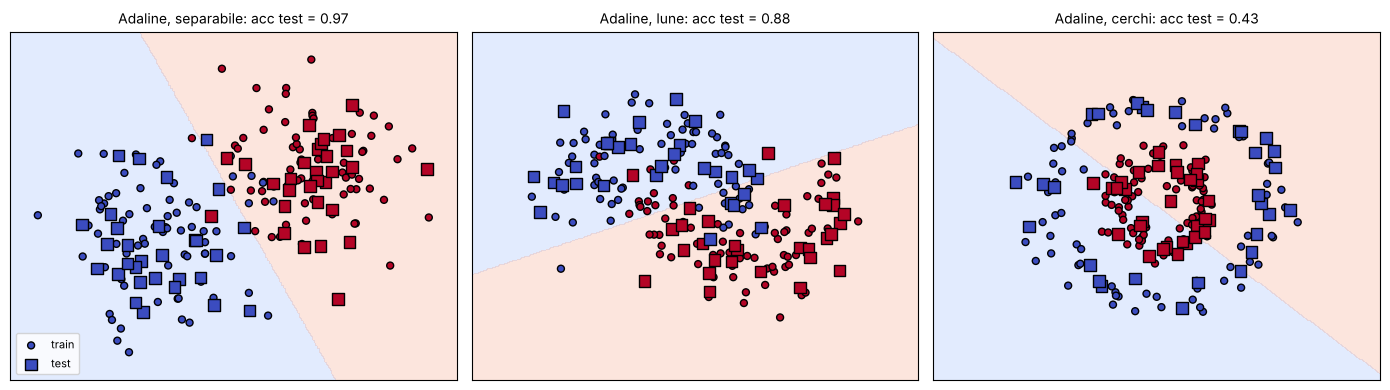

In [7]:
class AdalineCF(BaseEstimator, ClassifierMixin):
    # Adaline in closed form (minimi quadrati su y in {-1,+1}), poi soglia sul segno
    def fit(self, X, y):
        self.classes_ = np.unique(y)
        t = np.where(y == self.classes_[1], 1.0, -1.0)
        self.lin_ = LinearRegression().fit(X, t)
        return self
    def predict(self, X):
        return np.where(self.lin_.predict(X) >= 0, self.classes_[1], self.classes_[0])

scheda_grafica(make_pipeline(StandardScaler(), AdalineCF()), "Adaline,")

### Approfondimento: Adaline

**Perché si chiama così?** ADAptive LInear NEuron. *Linear* perché l'errore si calcola sull'uscita lineare $z$, non sulla soglia.

**La differenza in una riga** (nb 02, *Key Difference from the Perceptron*): il Perceptron dice solo "giusto o sbagliato", l'Adaline dice "**di quanto**" hai sbagliato. Per questo esiste una funzione costo liscia da minimizzare:
$$J(\mathbf{w})=\frac12\sum_n \big(y_n - z_n\big)^2,\qquad z_n=\mathbf{w}^\top\mathbf{x}_n$$

**Due modi per trovare il minimo**
- **Closed form**: $\mathbf{w}=\mathbf{X}^{+}\mathbf{y}$ con la pseudo-inversa (nb 01, *Moore-Penrose*). Un colpo solo.
- **Gradient descent**: fai piccoli passi in discesa, $\mathbf{w}\leftarrow\mathbf{w}+\eta\,\mathbf{X}^\top(\mathbf{y}-\mathbf{z})$. È un processo.

**Varianti del gradient descent** (nb 02, *Large-scale learning*):
| Variante | Punti usati per ogni passo | Pro / contro |
|---|---|---|
| Batch GD | tutti gli $N$ | passi precisi, ma lenti con tanti dati |
| Mini-batch | un gruppetto (es. 32) | compromesso, il più usato |
| SGD | **uno solo** ($m=1$) | velocissimo, ma il costo "balla" |

Nel grafico il costo di SGD è misurato una volta per epoca, quindi lo vedi liscio: il "ballare" avviene tra un punto e l'altro. I due metodi usano $\eta$ diversi perché SGD fa un passo per punto.

**Il punto delicato è $\eta$**: troppo piccolo e ci mette una vita, troppo grande e **diverge** (il costo esplode). E con feature non standardizzate un $\eta$ unico va bene per una feature e malissimo per l'altra: per questo si standardizza (nb 02, *Best practices*).

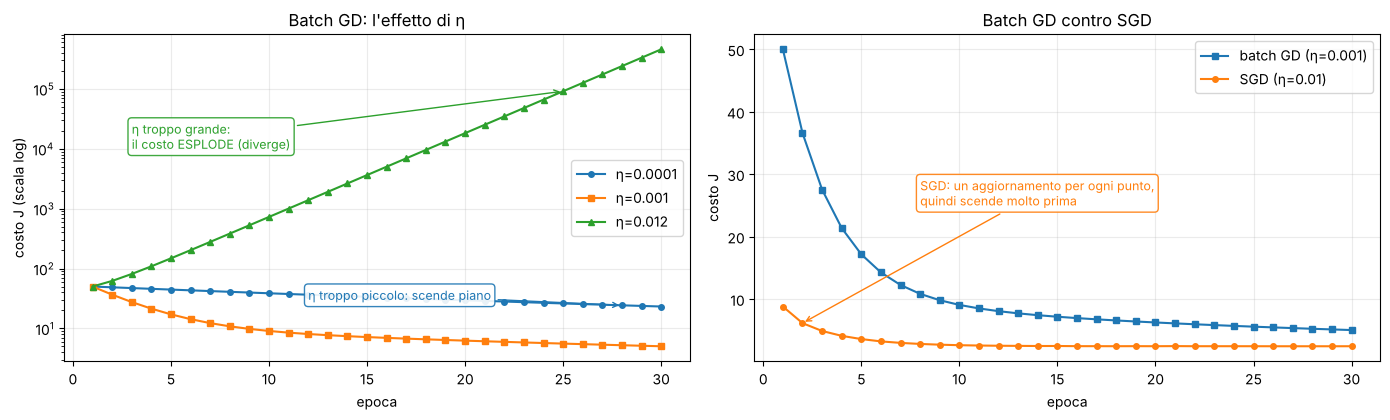

In [8]:
from sklearn.datasets import load_iris
ir = load_iris(); Xa = StandardScaler().fit_transform(ir.data[:100][:, [0, 2]])
ya = np.where(ir.target[:100] == 0, -1, 1)

def adaline_gd(X, y, eta, epoche=30):
    w = np.zeros(X.shape[1] + 1); J = []
    for _ in range(epoche):
        err = y - (X @ w[1:] + w[0])
        w[1:] += eta * X.T @ err; w[0] += eta * err.sum()
        J.append(0.5 * (err ** 2).sum())
    return J

def adaline_sgd(X, y, eta, epoche=30, seed=1):
    rng = np.random.RandomState(seed); w = np.zeros(X.shape[1] + 1); J = []
    for _ in range(epoche):
        for i in rng.permutation(len(y)):
            e = y[i] - (X[i] @ w[1:] + w[0]); w[1:] += eta * e * X[i]; w[0] += eta * e
        J.append(0.5 * ((y - (X @ w[1:] + w[0])) ** 2).sum())
    return J

fig, ax = plt.subplots(1, 2, figsize=(14, 4.3))
for eta, st in [(0.0001, "o-"), (0.001, "s-"), (0.012, "^-")]:
    ax[0].plot(range(1, 31), adaline_gd(Xa, ya, eta), st, ms=4, label=f"η={eta}")
ax[0].set_yscale("log"); ax[0].set_xlabel("epoca"); ax[0].set_ylabel("costo J (scala log)"); ax[0].legend()
ax[0].set_title("Batch GD: l'effetto di η")
annota(ax[0], "η troppo grande:\nil costo ESPLODE (diverge)", (25, adaline_gd(Xa, ya, 0.012)[24]), (3, 1e4), "tab:green")
annota(ax[0], "η troppo piccolo: scende piano", (28, adaline_gd(Xa, ya, 0.0001)[27]), (12, 30), "tab:blue")
ax[1].plot(range(1, 31), adaline_gd(Xa, ya, 0.001), "s-", ms=4, label="batch GD (η=0.001)")
ax[1].plot(range(1, 31), adaline_sgd(Xa, ya, 0.01), "o-", ms=4, label="SGD (η=0.01)")
ax[1].set_xlabel("epoca"); ax[1].set_ylabel("costo J"); ax[1].legend(); ax[1].set_title("Batch GD contro SGD")
annota(ax[1], "SGD: un aggiornamento per ogni punto,\nquindi scende molto prima", (2, adaline_sgd(Xa, ya, 0.01)[1]), (8, 25), "tab:orange")
plt.tight_layout(); plt.show()

## A3. Regressione logistica `[corso]`

- **Idea**: $z=\mathbf{w}^\top\mathbf{x}$, poi la **sigmoide** $\sigma(z)=1/(1+e^{-z})$ trasforma $z$ in una **probabilità** di classe positiva. Si decide con soglia 0.5 (modificabile).
- **Peculiarità**: restituisce **probabilità**, quindi puoi spostare la soglia per scegliere tra precision e recall. Si allena minimizzando la log-loss.
- **Forte**: modello di riferimento per cominciare. Probabilità, confine interpretabile (i pesi dicono quali feature contano), veloce. Regolarizzata di default.
- **Debole**: confine **lineare** nello spazio delle feature (si può curvare con `PolynomialFeatures`, come nel notebook 06).
- **Manopole**: `C` = **inverso** della regolarizzazione (C piccolo = più regolarizzato, `C=np.inf` = nessuna), penalità L1/L2.

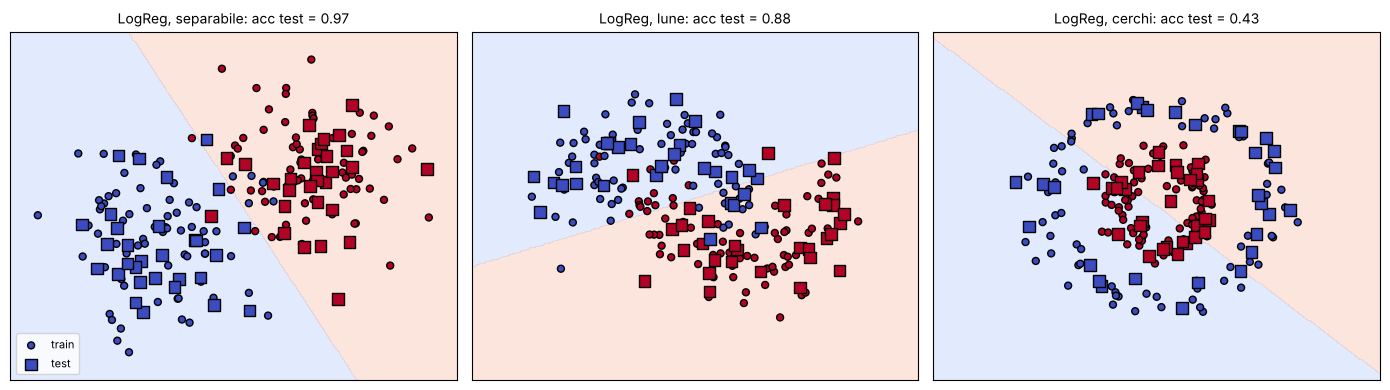

In [9]:
scheda_grafica(make_pipeline(StandardScaler(), LogisticRegression(C=1.0)), "LogReg,")

### Approfondimento: regressione logistica

**Perché "regressione" se classifica?** Perché prima *regredisce* un numero continuo, la probabilità, e solo dopo la soglia lo trasforma in classe.

**Da dove viene la sigmoide** (nb 02, *Odds ratio and logit*):
- **Odds**: $\frac{p}{1-p}$. Se $p=0.8$, gli odds sono $4$ ("4 a 1").
- **Logit**: $\log\frac{p}{1-p}$. Va da $-\infty$ a $+\infty$, quindi si può mettere uguale a una retta: $\log\frac{p}{1-p}=z=\mathbf{w}^\top\mathbf{x}$.
- Risolvendo per $p$ si ottiene la **sigmoide**: $p=\sigma(z)=\frac{1}{1+e^{-z}}$.

Valori da ricordare: $\sigma(0)=0.5$, $\sigma(2)\approx0.88$, $\sigma(-2)\approx0.12$.

**La differenza con Adaline** (nb 02, *Differences with ADALINE?*): la formula di aggiornamento ha la stessa forma, ma l'errore è $y-\sigma(z)$ invece di $y-z$, e il costo è la **log-loss** invece dell'errore quadratico.

**Il vantaggio pratico: la soglia si sposta.** Con la probabilità in mano puoi decidere "positivo se $p\ge 0.3$" invece di $0.5$. Abbassare la soglia aumenta il **recall** (trovi più positivi) e abbassa la **precision** (più falsi allarmi). Il secondo grafico lo mostra.

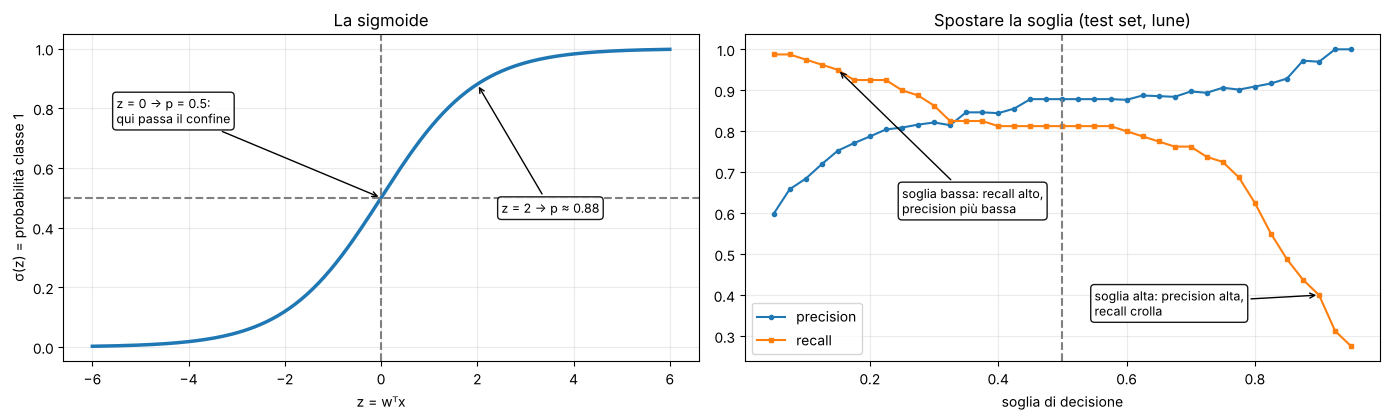

In [10]:
from sklearn.metrics import precision_score, recall_score
z = np.linspace(-6, 6, 200); sig = 1 / (1 + np.exp(-z))
Xl, yl = make_moons(400, noise=0.35, random_state=3)
Xltr, Xlte, yltr, ylte = train_test_split(Xl, yl, test_size=.4, stratify=yl, random_state=0)
lr = make_pipeline(StandardScaler(), LogisticRegression()).fit(Xltr, yltr)
p = lr.predict_proba(Xlte)[:, 1]
soglie = np.linspace(0.05, 0.95, 37)
P = [precision_score(ylte, p >= s, zero_division=1) for s in soglie]
R = [recall_score(ylte, p >= s) for s in soglie]

fig, ax = plt.subplots(1, 2, figsize=(14, 4.3))
ax[0].plot(z, sig, lw=2.5); ax[0].axhline(.5, ls="--", c="gray"); ax[0].axvline(0, ls="--", c="gray")
ax[0].set_xlabel("z = wᵀx"); ax[0].set_ylabel("σ(z) = probabilità classe 1"); ax[0].set_title("La sigmoide")
annota(ax[0], "z = 0 → p = 0.5:\nqui passa il confine", (0, .5), (-5.5, .75))
annota(ax[0], "z = 2 → p ≈ 0.88", (2, 1 / (1 + np.exp(-2))), (2.5, .45))
ax[1].plot(soglie, P, "o-", ms=3, label="precision"); ax[1].plot(soglie, R, "s-", ms=3, label="recall")
ax[1].axvline(.5, ls="--", c="gray"); ax[1].set_xlabel("soglia di decisione"); ax[1].legend()
ax[1].set_title("Spostare la soglia (test set, lune)")
annota(ax[1], "soglia bassa: recall alto,\nprecision più bassa", (.15, R[4]), (.25, .6))
annota(ax[1], "soglia alta: precision alta,\nrecall crolla", (.9, R[-3]), (.55, .35))
plt.tight_layout(); plt.show()

## A3b. Più di due classi `[corso]` (nb 03)

Perceptron e logistica nascono per **due** classi. Con $K$ classi ci sono tre strade:

| Strategia | Cosa allena | Quanti modelli | Come decide |
|---|---|---|---|
| **One-vs-Rest (OvR)** | "classe $k$ contro tutte le altre" | $K$ | vince il punteggio più alto |
| **One-vs-One (OvO)** | ogni coppia di classi | $K(K-1)/2$ | **voto** tra le coppie (pareggi possibili, nb 03) |
| **Nativo** (logistica multinomiale, LDA, k-NN) | un modello unico | 1 | probabilità per ogni classe |

**Softmax** (logistica multinomiale): trasforma $K$ punteggi in $K$ probabilità che sommano a 1:
$$p_k=\frac{e^{z_k}}{\sum_j e^{z_j}}$$
Esempio con $z=(2,\,1,\,0)$: $e^2\approx7.39$, $e^1\approx2.72$, $e^0=1$, somma $\approx11.11$, quindi $p\approx(0.665,\ 0.245,\ 0.090)$. Vince la classe 1, e sai anche **quanto** è sicuro.

Le etichette per la softmax si scrivono in **one-hot**: la classe 2 di 3 diventa $(0,1,0)$.

**Collegamento**: `SVC` usa OvO internamente (pagina sklearn 1.4), `LogisticRegression` è nativamente multinomiale.

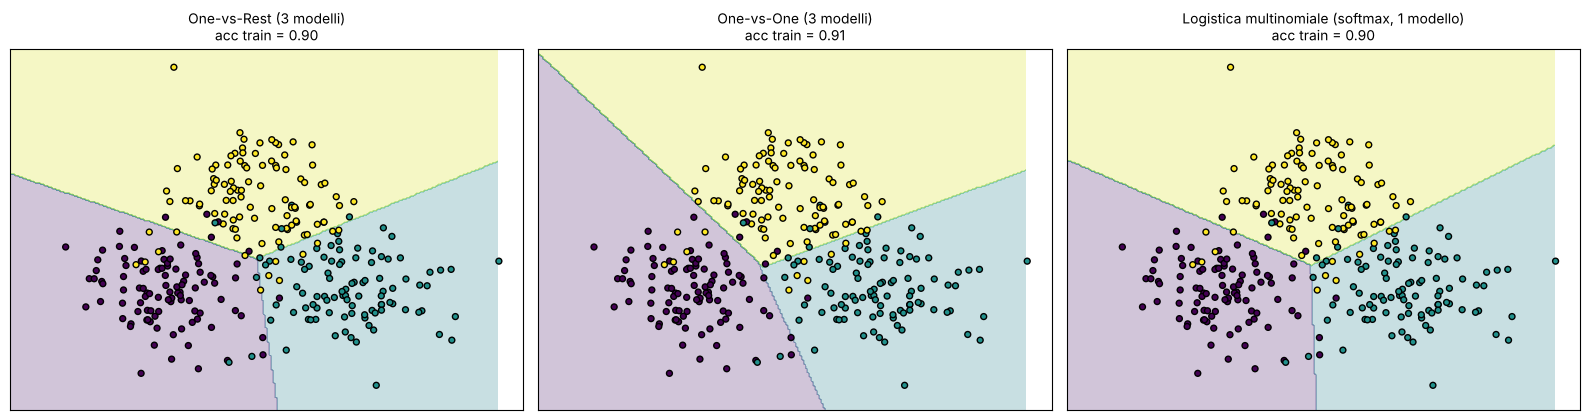

softmax di (2,1,0): [0.665 0.245 0.09 ]


In [11]:
from sklearn.multiclass import OneVsRestClassifier, OneVsOneClassifier
X3, y3 = make_blobs(300, centers=[[-2, 0], [2, 0], [0, 2.5]], cluster_std=1.0, random_state=1)
strategie = {
    "One-vs-Rest (3 modelli)": OneVsRestClassifier(make_pipeline(StandardScaler(), Perceptron(random_state=0))),
    "One-vs-One (3 modelli)": OneVsOneClassifier(make_pipeline(StandardScaler(), Perceptron(random_state=0))),
    "Logistica multinomiale (softmax, 1 modello)": make_pipeline(StandardScaler(), LogisticRegression()),
}
xx, yy = np.meshgrid(np.linspace(-5, 5, 250), np.linspace(-3.5, 7, 250))
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
for a, (nm, m) in zip(ax, strategie.items()):
    m.fit(X3, y3)
    a.contourf(xx, yy, m.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape), alpha=.25, cmap="viridis")
    a.scatter(*X3.T, c=y3, cmap="viridis", edgecolor="k", s=18)
    a.set_title(f"{nm}\nacc train = {m.score(X3, y3):.2f}", fontsize=10); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()
zz = np.array([2., 1., 0.]); print("softmax di (2,1,0):", (np.exp(zz) / np.exp(zz).sum()).round(3))

## A3c. Feature mapping: curvare un modello lineare `[corso]` (nb 04, slide *Kernels*)

**Idea**: se il confine nello spazio originale è curvo, **aggiungi colonne** (per esempio $x_1^2$, $x_2^2$, $x_1x_2$) e usa lo stesso modello lineare nel nuovo spazio. Nello spazio nuovo il confine è un piano, in quello vecchio diventa una curva.

Esempio dalle slide: per i cerchi basta $\phi(\mathbf{x})=(x_1,\,x_2,\,x_1^2+x_2^2)$. La terza coordinata è il **raggio al quadrato**: il cerchio interno ha raggio piccolo, quello esterno grande, quindi una soglia su $r^2$ li separa.

**Il prezzo**: il numero di colonne esplode con il grado (vedi la tabella nella Parte B, *curse of dimensionality*). È per questo che esistono i **kernel**, che fanno la stessa cosa senza costruire le colonne.

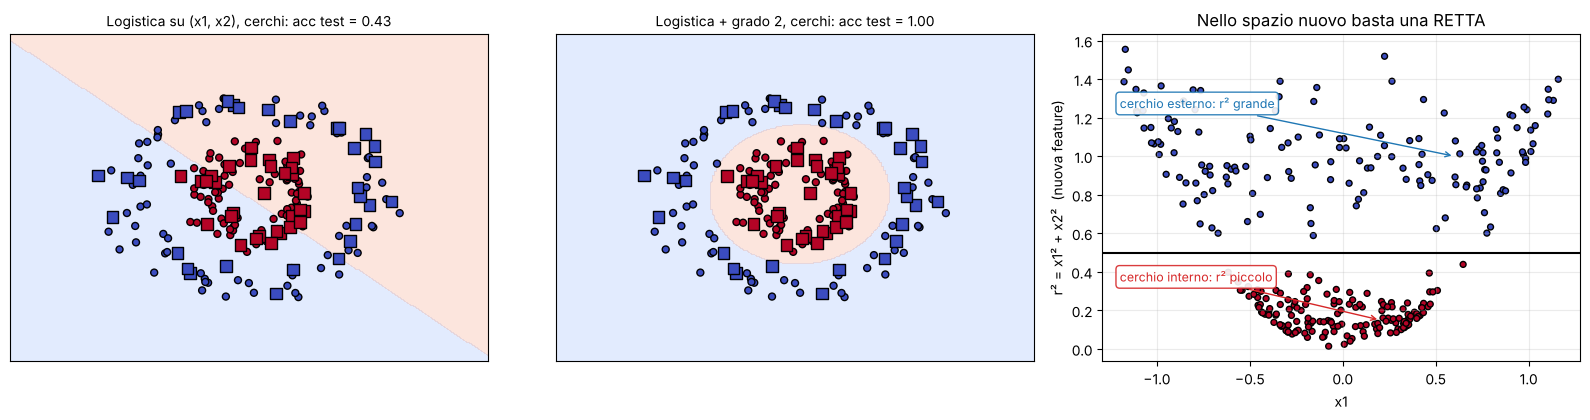

In [12]:
Xc2, yc2 = make_circles(300, noise=0.1, factor=0.4, random_state=0)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
disegna(ax[0], make_pipeline(StandardScaler(), LogisticRegression()), "cerchi", "Logistica su (x1, x2),")
disegna(ax[1], make_pipeline(PolynomialFeatures(2), StandardScaler(), LogisticRegression()), "cerchi", "Logistica + grado 2,")
r2 = (Xc2 ** 2).sum(1)
ax[2].scatter(Xc2[:, 0], r2, c=yc2, cmap=CMAP, edgecolor="k", s=18)
ax[2].axhline(0.5, c="k", lw=1.5); ax[2].set_xlabel("x1"); ax[2].set_ylabel("r² = x1² + x2²  (nuova feature)")
ax[2].set_title("Nello spazio nuovo basta una RETTA")
annota(ax[2], "cerchio esterno: r² grande", (0.6, 1.0), (-1.2, 1.25), "tab:blue")
annota(ax[2], "cerchio interno: r² piccolo", (0.2, 0.15), (-1.2, 0.35), "tab:red")
plt.tight_layout(); plt.show()

**Prova tu.** Cambia `C` in `0.001` e in `1000` e guarda come cambia l'inclinazione della retta (non la forma: resta una retta).

**Perceptron, Adaline e logistica in una frase**: stesso $z=\mathbf{w}^\top\mathbf{x}$, tre modi diversi di *misurare l'errore*: errore di soglia (0/1), errore quadratico su $z$, log-loss su $\sigma(z)$.

## A4. SVM lineare `[corso]`

- **Idea**: tra tutte le rette che separano i dati, scegli quella con il **margine massimo** (la striscia più larga senza punti in mezzo, larga $2/\|\mathbf{w}\|$). * Margin = space between the line to the first vector, larger it is better the algorithm is working
- **Peculiarità**: il confine dipende **solo dai support vector**, cioè i pochi punti che toccano il margine. Gli altri si possono cancellare senza cambiare nulla.
- **Forte**: scelta "ben definita" tra le infinite rette (a differenza del Perceptron). Ottima generalizzazione con dati in alta dimensione.
- **Debole**: nessuna probabilità diretta. `SVC` va lento con decine di migliaia di righe `[corso]`/sklearn. Lineare.
- **Manopole**: `C` (margine morbido: C grande = poca tolleranza agli errori, margine stretto; C piccolo = margine largo).
Whats a vector, a vector V is about the feature of our Matrix in input.
Why stands for Support vectors? Because we consider the margin line the one that is not fully dotted like a bridge and we consider the vectors inside the margin and on the margin line like the columns that supports this margin, if we move our support vectors outside the margin it falls and it moves also.
This algorithm take in input also an Hyperparameter C and it can change a lot about the margin (smaller or larger)

> **Nota del tutor sulle tue note in inglese.** L'idea del ponte e dei pilastri è giusta. Tre piccole precisazioni:
> 1. *"a vector V is about the feature of our Matrix"*: qui un **vettore è un punto**, cioè **una riga** della matrice con tutte le sue feature (un esempio di training), non una colonna.
> 2. *"the margin line the one that is not fully dotted"*: la linea **piena** è il **confine di decisione**; le due linee **tratteggiate** sono i **bordi del margine**. I support vector stanno sulle tratteggiate, dentro la striscia o dalla parte sbagliata.
> 3. *"larger it is better the algorithm is working"*: un margine largo di solito generalizza meglio, ma con `C` piccolo lo ottieni **accettando più errori** sul training. È un compromesso da scegliere con la cross-validation, non "più largo = sempre meglio".

## Quanti support vector? Pochi o tanti

Un **support vector** è un punto di training che sta sul bordo del margine, dentro il margine o dalla parte sbagliata. Il confine dipende **solo da questi punti**: se togli un punto lontano, il confine non cambia.

Il numero di support vector **non è un obiettivo**, è un sintomo. Va letto insieme a accuracy di train e di test:

| Situazione | Support vector | Cosa significa |
|---|---|---|
| Dati separabili, `C` alto | pochi | problema pulito, modello semplice, predizione veloce |
| `C` piccolo | molti | margine largo, più regolarizzato (più bias, meno varianza) |
| Classi sovrapposte | molti | dati difficili, nessun margine pulito |
| RBF con `gamma` altissimo | quasi tutti | overfitting: train alto, test basso |

Per scegliere `C` e `gamma` **non** si contano i support vector: si usa la validation curve o la GridSearchCV.

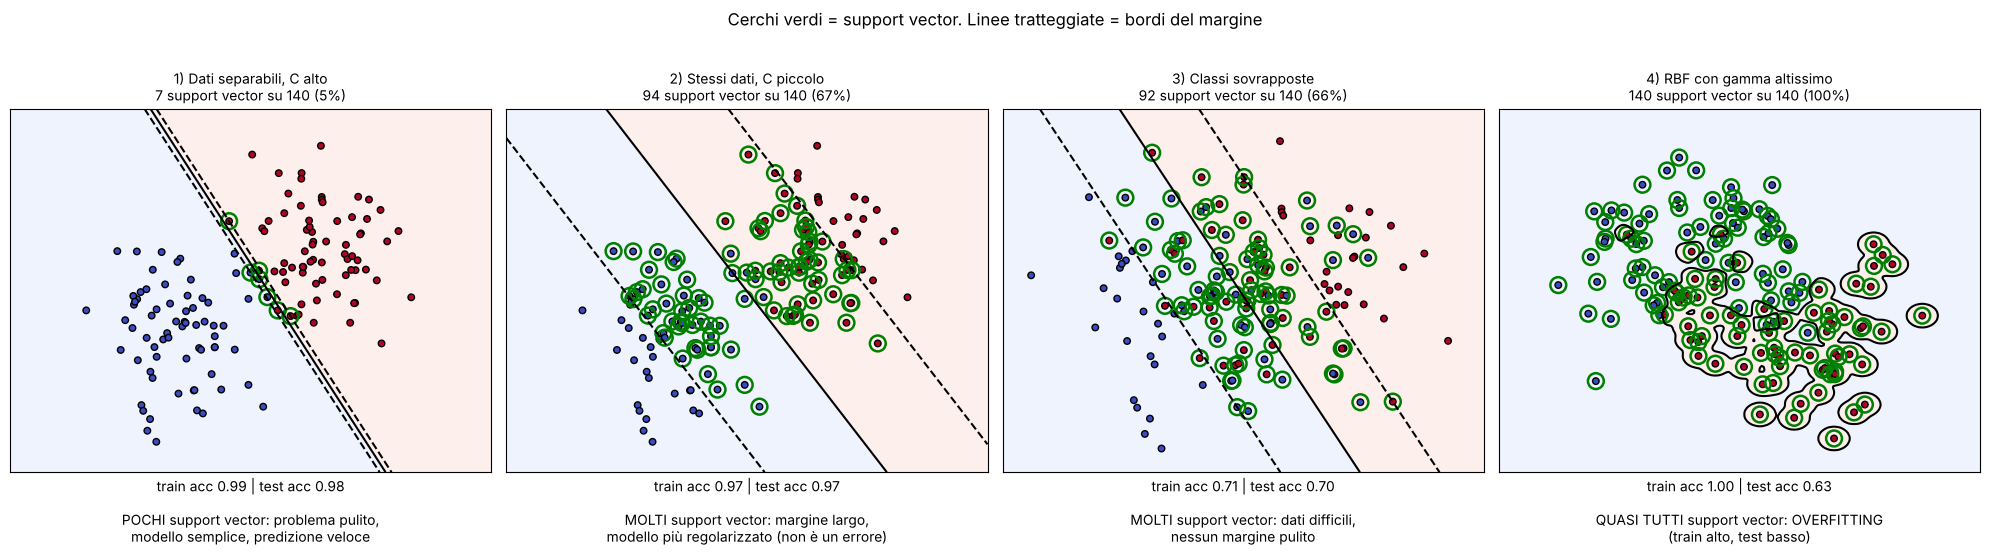

In [13]:
import numpy as np, matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

casi = [
    ("1) Dati separabili, C alto", make_blobs(200, centers=[[-2,-1],[2,1]], cluster_std=1.0, random_state=0),
     SVC(kernel="linear", C=100), "POCHI support vector: problema pulito,\nmodello semplice, predizione veloce"),
    ("2) Stessi dati, C piccolo", make_blobs(200, centers=[[-2,-1],[2,1]], cluster_std=1.0, random_state=0),
     SVC(kernel="linear", C=0.01), "MOLTI support vector: margine largo,\nmodello più regolarizzato (non è un errore)"),
    ("3) Classi sovrapposte", make_blobs(200, centers=[[-1,-0.5],[1,0.5]], cluster_std=1.6, random_state=0),
     SVC(kernel="linear", C=1), "MOLTI support vector: dati difficili,\nnessun margine pulito"),
    ("4) RBF con gamma altissimo", make_moons(200, noise=0.3, random_state=0),
     SVC(kernel="rbf", C=1, gamma=100), "QUASI TUTTI support vector: OVERFITTING\n(train alto, test basso)"),
]

fig, axs = plt.subplots(1, 4, figsize=(20, 5.4))
for ax, (titolo, (X, y), svm, nota) in zip(axs, casi):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, stratify=y, random_state=0)
    sc = StandardScaler().fit(Xtr); Xtr_s, Xte_s = sc.transform(Xtr), sc.transform(Xte)
    svm.fit(Xtr_s, ytr)
    xx, yy = np.meshgrid(np.linspace(-3, 3, 250), np.linspace(-3, 3, 250))
    D = svm.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, D > 0, alpha=.15, cmap="coolwarm")
    ax.contour(xx, yy, D, levels=[0], colors="k")
    if svm.kernel == "linear":
        ax.contour(xx, yy, D, levels=[-1, 1], colors="k", linestyles="--")
    ax.scatter(*Xtr_s.T, c=ytr, cmap="coolwarm", edgecolor="k", s=22)
    ax.scatter(*svm.support_vectors_.T, s=130, facecolors="none", edgecolors="g", linewidths=1.8)
    n_sv, n = len(svm.support_vectors_), len(Xtr_s)
    ax.set_title(f"{titolo}\n{n_sv} support vector su {n} ({100*n_sv/n:.0f}%)", fontsize=10)
    ax.set_xlabel(f"train acc {svm.score(Xtr_s, ytr):.2f} | test acc {svm.score(Xte_s, yte):.2f}\n\n{nota}", fontsize=10)
    ax.set_xlim(-3, 3); ax.set_ylim(-3, 3); ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Cerchi verdi = support vector. Linee tratteggiate = bordi del margine", y=1.02)
plt.tight_layout(); plt.show()

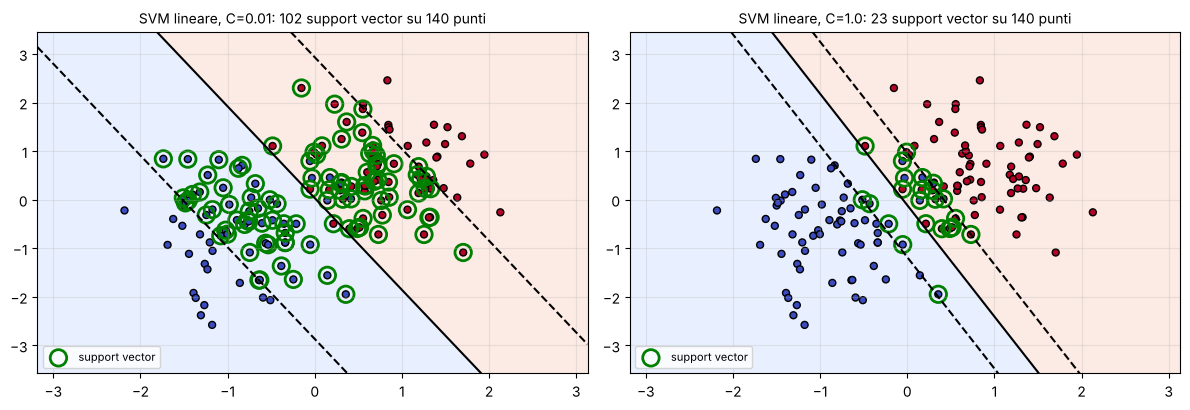

In [14]:
svm_lin = make_pipeline(StandardScaler(), SVC(kernel="linear", C=1.0))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
Xtr, Xte, ytr, yte = SPLIT["separabile"]
for a, C in zip(ax, [0.01, 1.0]):
    mod = make_pipeline(StandardScaler(), SVC(kernel="linear", C=C)).fit(Xtr, ytr)
    sc, svc = mod[0], mod[1]
    Xs = sc.transform(Xtr)
    xx, yy = np.meshgrid(np.linspace(Xs[:, 0].min() - 1, Xs[:, 0].max() + 1, 200),
                         np.linspace(Xs[:, 1].min() - 1, Xs[:, 1].max() + 1, 200))
    D = svc.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    a.contourf(xx, yy, D > 0, alpha=.2, cmap=CMAP)
    a.contour(xx, yy, D, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"])
    a.scatter(*Xs.T, c=ytr, cmap=CMAP, edgecolor="k", s=25)
    a.scatter(*svc.support_vectors_.T, s=140, facecolors="none", edgecolors="g", linewidths=2, label="support vector")
    a.set_title(f"SVM lineare, C={C}: {len(svc.support_vectors_)} support vector su {len(Xs)} punti", fontsize=10)
    a.legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()

**Cosa guardare.** Le linee tratteggiate sono i bordi del margine, la linea piena il confine. Con **C piccolo** il margine è largo e i support vector sono molti (tollera errori dentro il margine). Con **C grande** il margine si stringe e i support vector diventano pochi.

## A5. SVM con kernel (RBF) `[corso]`

- **Idea**: stessa SVM, ma al posto del prodotto scalare usa una funzione **kernel**. Il kernel RBF misura la somiglianza $\exp(-\gamma\|\mathbf{x}-\mathbf{z}\|^2)$ e permette confini **curvi** senza costruire a mano le feature (*kernel trick*).
- **Peculiarità**: ogni support vector fa da "centro": il modello **si adatta ai dati**, non ha centri fissi scelti a mano `[corso]` (nb 08: *"Gaussian Kernel is not the same as Gaussian features"*).
- **Forte**: confini molto flessibili con poche manopole. Funziona bene su dataset medi.
- **Debole**: lento con molti campioni, **non scala bene**. Molto sensibile a `gamma` e `C`: se esageri va in **overfitting**. Poco interpretabile.
- **Manopole**: `gamma` (raggio d'influenza di ogni punto: grande = confine frastagliato), `C`.

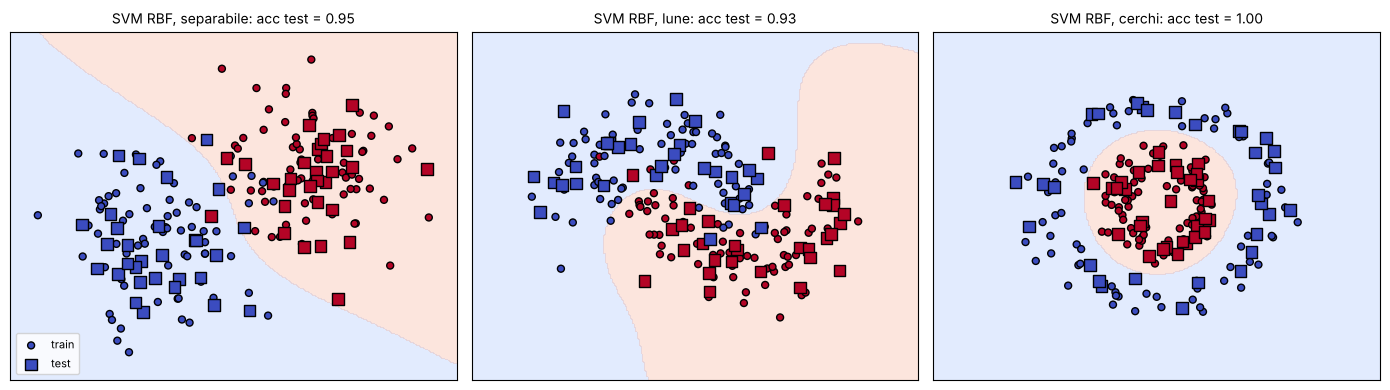

In [15]:
scheda_grafica(make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma="scale")), "SVM RBF,")

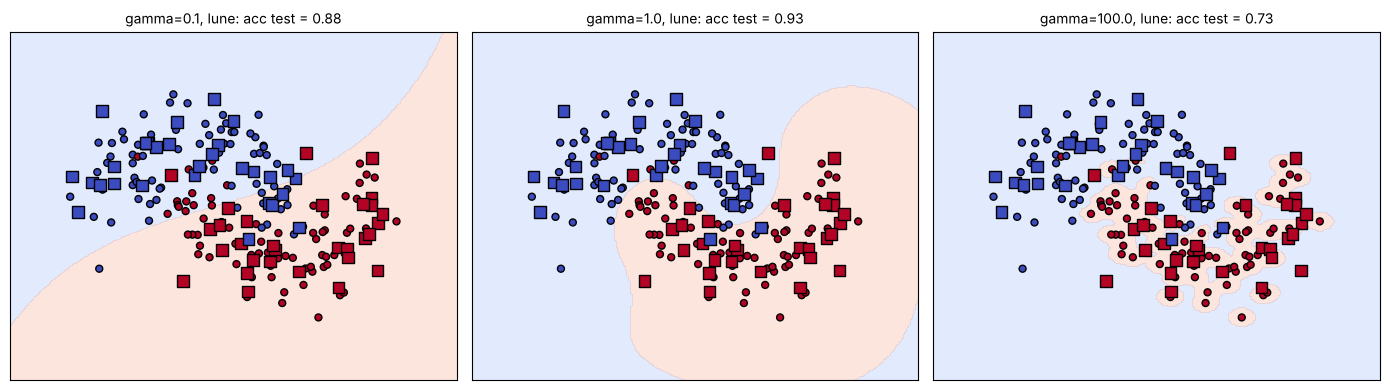

In [16]:
fig, axs = plt.subplots(1, 3, figsize=(14, 4))
for ax, g in zip(axs, [0.1, 1.0, 100.0]):
    disegna(ax, make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma=g)), "lune", f"gamma={g},")
plt.tight_layout(); plt.show()

**Cosa guardare.** `gamma` piccolo = confine quasi retto (underfitting), `gamma` giusto = confine ragionevole, `gamma=100` = isole attorno ai singoli punti (overfitting). Controlla anche l'accuracy di test: scende quando il confine "impara a memoria".

### Approfondimento: kernel e SVM RBF (slide *Kernels and Non-Parametric Models*)

**Cos'è un kernel?** Una funzione $k(\mathbf{x},\mathbf{z})$ che dà un **numero di somiglianza** tra due punti. Formalmente è un prodotto scalare in uno spazio di feature: $k(\mathbf{x},\mathbf{z})=\phi(\mathbf{x})^\top\phi(\mathbf{z})$.

| Kernel | Formula | Intuizione |
|---|---|---|
| Lineare | $\mathbf{x}^\top\mathbf{z}$ | coseno dell'angolo × lunghezze |
| Polinomiale | $(\mathbf{x}^\top\mathbf{z}+c)^p$ | come `PolynomialFeatures` di grado $p$ |
| RBF / gaussiano | $\exp(-\gamma\|\mathbf{x}-\mathbf{z}\|^2)$ | 1 se i punti coincidono, verso 0 se sono lontani |

**Il kernel trick**: se un algoritmo usa i dati **solo tramite prodotti scalari**, puoi sostituirli con $k$ e lavorare in uno spazio enorme (per l'RBF, infinito) senza costruirlo. Funziona per la SVM, ma anche per **kernel perceptron**, **kernel ridge regression** e **kernel PCA** (stesse slide).

**Come predice la SVM con kernel** (slide *Prediction with a kernel SVM*):
$$f(\mathbf{x})=\sum_{n\in S}\alpha_n t_n\, k(\mathbf{x}_n,\mathbf{x})+w_0$$
Somma di "somiglianze" con i **soli support vector** $S$. Per questo è **non parametrica**: più support vector, più termini, più memoria e lentezza.

**`gamma` in una frase**: quanto in fretta la somiglianza cala con la distanza. Si scrive anche $\gamma=\frac{1}{2\sigma^2}$, con $\sigma$ = "raggio d'influenza". Sotto lo vedi.

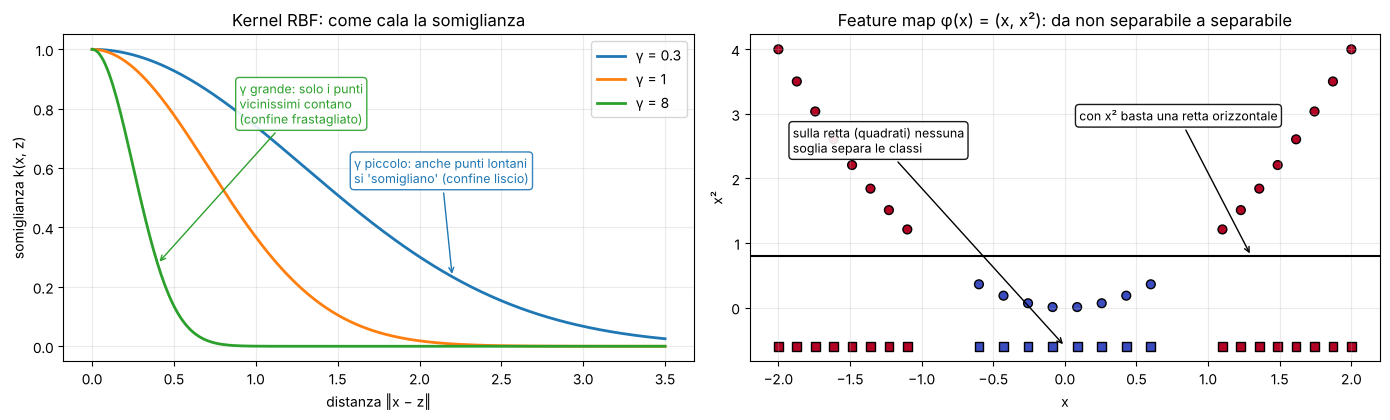

In [17]:
d = np.linspace(0, 3.5, 300)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.3))
for g in [0.3, 1, 8]:
    ax[0].plot(d, np.exp(-g * d ** 2), lw=2, label=f"γ = {g}")
ax[0].set_xlabel("distanza ‖x − z‖"); ax[0].set_ylabel("somiglianza k(x, z)"); ax[0].legend()
ax[0].set_title("Kernel RBF: come cala la somiglianza")
annota(ax[0], "γ grande: solo i punti\nvicinissimi contano\n(confine frastagliato)", (0.4, np.exp(-8 * .16)), (0.9, .75), "tab:green")
annota(ax[0], "γ piccolo: anche punti lontani\nsi 'somigliano' (confine liscio)", (2.2, np.exp(-.3 * 2.2 ** 2)), (1.6, .55), "tab:blue")
x1 = np.r_[np.linspace(-2, -1.1, 8), np.linspace(-.6, .6, 8), np.linspace(1.1, 2, 8)]
t1 = np.r_[np.ones(8), -np.ones(8), np.ones(8)]
ax[1].scatter(x1, x1 ** 2, c=t1, cmap=CMAP, edgecolor="k", s=40); ax[1].scatter(x1, np.zeros_like(x1) - .6, c=t1, cmap=CMAP, edgecolor="k", s=40, marker="s")
ax[1].axhline(0.8, c="k"); ax[1].set_xlabel("x"); ax[1].set_ylabel("x²")
ax[1].set_title("Feature map φ(x) = (x, x²): da non separabile a separabile")
annota(ax[1], "sulla retta (quadrati) nessuna\nsoglia separa le classi", (0, -.6), (-1.9, 2.4))
annota(ax[1], "con x² basta una retta orizzontale", (1.3, .8), (.1, 2.9))
plt.tight_layout(); plt.show()

## A6. k-NN `[corso]`

- **Idea**: per classificare un punto guarda i **K punti di training più vicini** e vota.
- **Peculiarità**: **non c'è training** e **non ha pesi**: il modello *è* il dataset. Modello **non parametrico**: la complessità cresce con i dati `[corso]`.
- **Forte**: semplicissimo, estensione immediata a più classi, confini di forma qualunque, funziona con **qualunque distanza** (anche custom, vedi esercizio DNA) `[corso]`.
- **Debole**: deve tenere in memoria **tutto** il training e **ogni predizione è lenta** `[corso]`. Sensibile alla scala delle feature e a quelle inutili. Con molte dimensioni le distanze perdono significato `[mio]`.
- **Manopole**: `n_neighbors` = K, che fa da **regolarizzazione**: più K, più confine liscio `[corso]`. Anche la metrica.

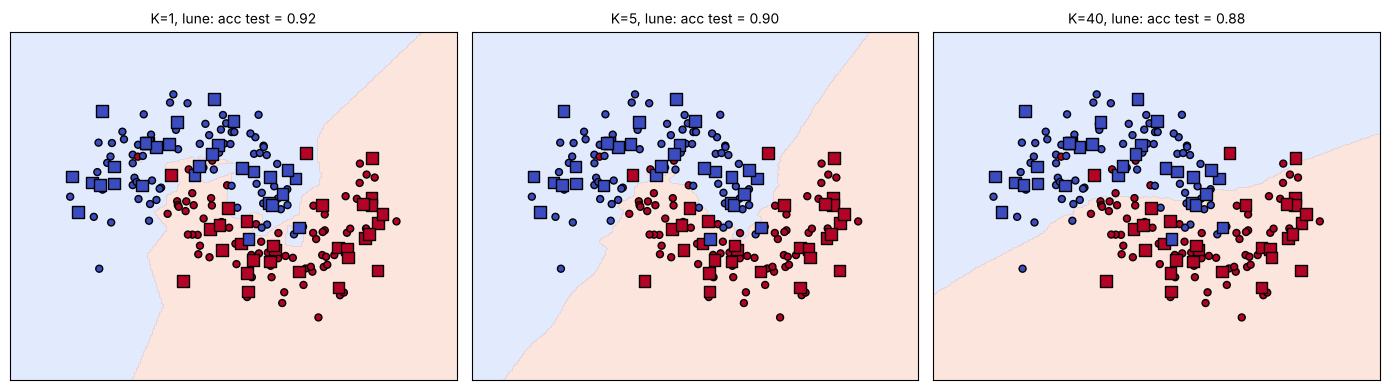

In [18]:
fig, axs = plt.subplots(1, 3, figsize=(14, 4))
for ax, k in zip(axs, [1, 5, 40]):
    disegna(ax, make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)), "lune", f"K={k},")
plt.tight_layout(); plt.show()

**Cosa guardare.** `K=1` impara a memoria ogni singolo punto (confine frastagliato, overfitting). `K=40` è troppo liscio (underfitting). Questa è la stessa idea di `gamma` nella SVM o di `C` nella logistica: **una manopola che dosa la complessità**.

### Approfondimento: k-NN (nb 04, nb 08, slide *Nearest Neighbors*, sklearn 1.6)

**Cosa riceve e cosa restituisce.** Hai `X_train` con il suo `y_train`. Arriva una **riga nuova** $\mathbf{x}$, **senza target**. Tre passi:
1. calcola la distanza da $\mathbf{x}$ a **ogni** riga di training;
2. prende le $K$ righe più vicine;
3. guarda **i loro target** e vota (classificazione) o fa la media (regressione).

`fit` non calcola niente: **memorizza** e basta. Tutto il lavoro avviene in `predict`.

**Le manopole**
- `n_neighbors` = $K$: piccolo = confine frastagliato (overfitting), grande = liscio (underfitting).
- `weights`: `'uniform'` (ogni vicino vale 1) o `'distance'` (peso $1/d$: i più vicini contano di più, e i pareggi diventano quasi impossibili).
- `metric`: euclidea $\sqrt{\sum_j (x_j-z_j)^2}$, Manhattan $\sum_j|x_j-z_j|$, oppure una distanza custom (esercizio DNA del nb 08).
- `algorithm` (`brute`, `kd_tree`, `ball_tree`, `auto`): cambia **solo la velocità** di ricerca, non il risultato.

**K dispari?** Con **due** classi evita i pareggi nel voto. Con tre o più classi non basta. Il valore di $K$ si sceglie comunque con la cross-validation.

**Perché non c'è un "punto di partenza"?** Perché non c'è allenamento iterativo: niente pesi iniziali casuali. A parità di dati, $K$ e distanza, il risultato è sempre lo stesso.

**Il problema delle dimensioni** (slide *Curse of dimensionality for KNN*): con $N$ punti sparsi uniformemente in $[0,1]^D$, i $K$ vicini stanno in un cubo di lato circa
$$\ell \approx \left(\tfrac{K}{N}\right)^{1/D}$$
Con $N=1000$ e $K=10$: in 1D $\ell=0.01$ (vicinissimi), in 10D $\ell\approx0.63$ (il "vicinato" copre più di metà di ogni asse!). I vicini **non sono più vicini**. Il secondo grafico lo mostra.

,x1,x2,y,"distanza da (3, 1.5)",rango
0,1,1,A,2.06,2
1,2,1,A,1.12,1
2,4,4,B,2.69,3
3,5,4,B,3.20,4
4,5,5,B,4.03,5


K=1: vicini = ['A']  ->  predizione A
K=3: vicini = ['A', 'A', 'B']  ->  predizione A
K=5: vicini = ['A', 'A', 'B', 'B', 'B']  ->  predizione B


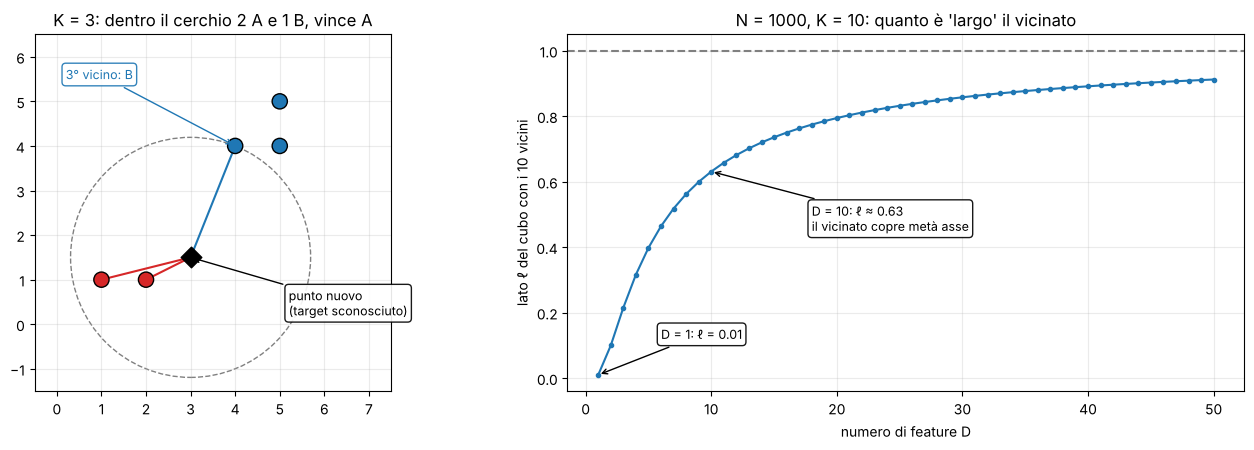

In [19]:
Xk = np.array([[1, 1], [2, 1], [4, 4], [5, 4], [5, 5]]); yk = np.array(["A", "A", "B", "B", "B"])
q = np.array([3, 1.5]); dist = np.sqrt(((Xk - q) ** 2).sum(1))
tab_knn = pd.DataFrame({"x1": Xk[:, 0], "x2": Xk[:, 1], "y": yk, "distanza da (3, 1.5)": dist.round(2)})
tab_knn["rango"] = tab_knn["distanza da (3, 1.5)"].rank().astype(int)
display(tab_knn)
for K in [1, 3, 5]:
    knn = KNeighborsClassifier(n_neighbors=K).fit(Xk, yk)
    print(f"K={K}: vicini = {[str(v) for v in yk[np.argsort(dist)[:K]]]}  ->  predizione {knn.predict([q])[0]}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
col = np.where(yk == "A", "tab:red", "tab:blue")
ax[0].scatter(*Xk.T, c=col, s=120, edgecolor="k", zorder=3); ax[0].scatter(*q, marker="D", c="k", s=110, zorder=4)
r3 = np.sort(dist)[2]
ax[0].add_patch(plt.Circle(q, r3, fill=False, ls="--", color="gray"))
for i in np.argsort(dist)[:3]:
    ax[0].plot([q[0], Xk[i, 0]], [q[1], Xk[i, 1]], c=col[i], lw=1.5)
ax[0].set_aspect("equal"); ax[0].set_xlim(-0.5, 7.5); ax[0].set_ylim(-1.5, 6.5)
ax[0].set_title("K = 3: dentro il cerchio 2 A e 1 B, vince A")
annota(ax[0], "punto nuovo\n(target sconosciuto)", tuple(q), (5.2, 0.2))
annota(ax[0], "3° vicino: B", (4, 4), (0.2, 5.5), "tab:blue")
Ds = np.arange(1, 51); ell = (10 / 1000) ** (1 / Ds)
ax[1].plot(Ds, ell, "o-", ms=3); ax[1].axhline(1, ls="--", c="gray")
ax[1].set_xlabel("numero di feature D"); ax[1].set_ylabel("lato ℓ del cubo con i 10 vicini")
ax[1].set_title("N = 1000, K = 10: quanto è 'largo' il vicinato")
annota(ax[1], f"D = 10: ℓ ≈ {ell[9]:.2f}\nil vicinato copre metà asse", (10, ell[9]), (18, .45))
annota(ax[1], "D = 1: ℓ = 0.01", (1, ell[0]), (6, .12))
plt.tight_layout(); plt.show()

## A7. LDA come classificatore `[mio]` + `[corso]` per la parte di riduzione

- **Idea**: assume che ogni classe sia una nuvola gaussiana con la **stessa covarianza**; il confine che ne deriva è una retta/iperpiano `[mio]`.
- **Peculiarità**: è sia un classificatore sia (soprattutto nel corso) un metodo di **riduzione di dimensioni supervisionato**: cerca la direzione che massimizza il **Fisher score**, cioè separa le medie delle classi e rimpicciolisce la varianza dentro ogni classe `[corso]` (nb 09).
- **Forte**: veloce, nessuna manopola da tarare, riduce a **al massimo C−1 dimensioni** `[corso]`.
- **Debole**: confine lineare; l'ipotesi gaussiana a covarianza comune può non valere `[mio]`.
- **Manopole**: `n_components` (come riduzione), `solver`.

Il suo uso nel progetto è la parte B (riduzione). Qui lo vediamo come classificatore per confronto.

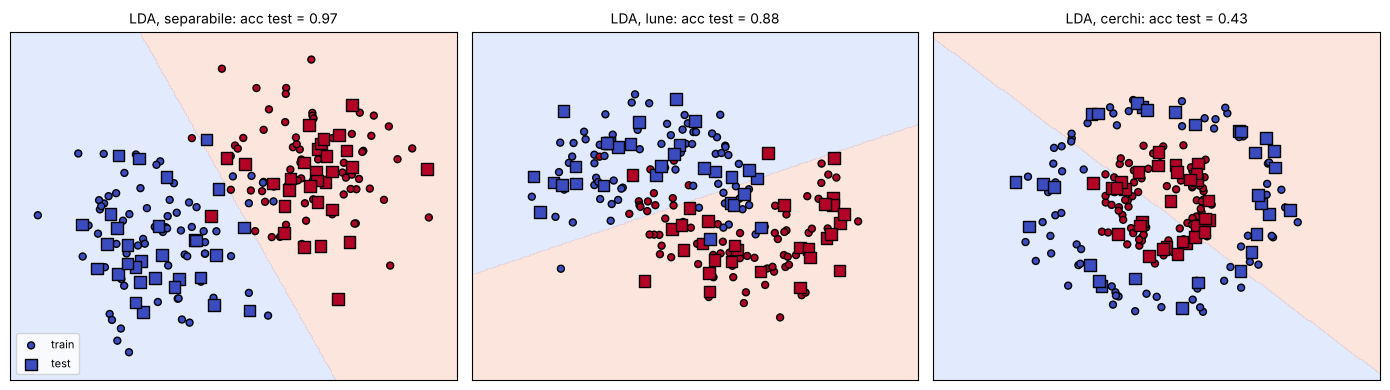

In [20]:
scheda_grafica(make_pipeline(StandardScaler(), LinearDiscriminantAnalysis()), "LDA,")

### Approfondimento: LDA (e QDA) come classificatori (sklearn 1.2, nb 09)

**Cos'è una "nuvola gaussiana"?** I punti di una classe si ammassano attorno a un **centro** (media $\boldsymbol\mu$) e si diradano allontanandosi, con forma ovale descritta dalla **covarianza** $\Sigma$ (quanto è larga in ogni direzione e se è inclinata). In 1D è la campana.

**Come classifica**: descrive ogni classe come una nuvola gaussiana e assegna il punto nuovo alla nuvola a cui "somiglia" di più (modello **generativo**: modella $P(\mathbf{x}\mid y)$).
- **LDA**: tutte le classi hanno **la stessa forma** $\Sigma$, cambia il centro: il confine è una **retta**.
- **QDA**: ogni classe ha **la sua forma** $\Sigma_k$: il confine è una **curva** (quadratica). QDA non compare nei notebook del prof, la cito solo per confronto `[mio]`. Nel grafico sotto una classe piccola sta dentro una grande: nessuna retta può separarle, la curva della QDA sì.

**Cosa ha in più rispetto a perceptron e logistica?**

| | Perceptron | Logistica | LDA |
|---|---|---|---|
| Output | classe | classe e probabilità | classe e probabilità |
| Allenamento | iterativo | iterativo | formula chiusa (medie e covarianze) |
| Ipotesi sui dati | nessuna | nessuna | classi gaussiane, stessa forma |
| Multiclasse | OvR/OvO | nativa (softmax) | nativa |
| **Riduce le dimensioni** | no | no | **sì, usando le etichette** (Parte B) |

Se l'ipotesi gaussiana vale, LDA funziona bene anche con pochi dati; se non vale, la logistica è più robusta `[mio]`. Il vero "in più" per il progetto è la riduzione di dimensioni.

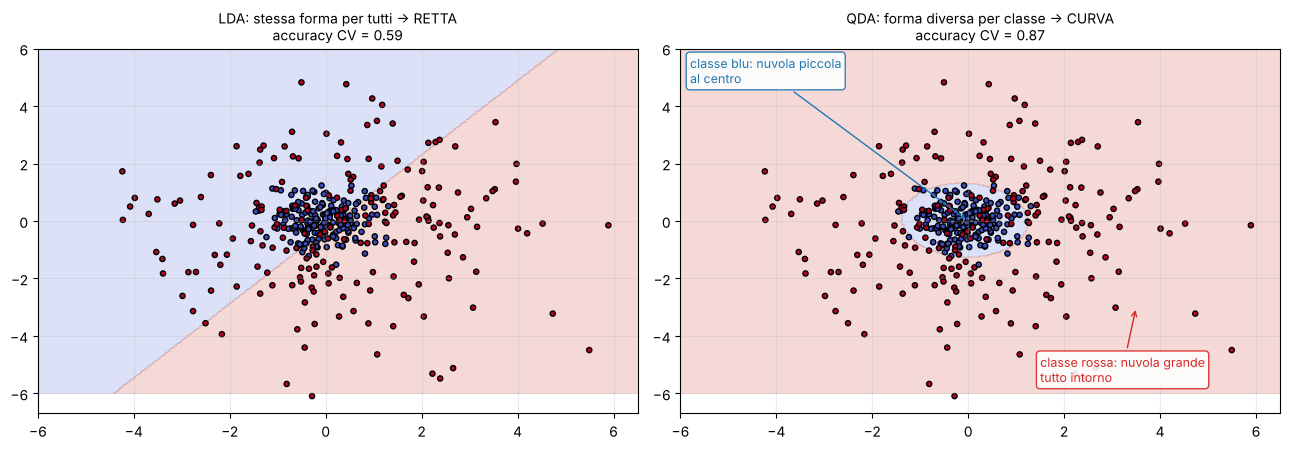

In [21]:
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
rng = np.random.RandomState(0)
A = rng.multivariate_normal([0, 0], [[0.3, 0], [0, 0.3]], 200)
B = rng.multivariate_normal([0.5, 0], [[4, 0], [0, 4]], 200)
Xq = np.r_[A, B]; yq = np.r_[np.zeros(200), np.ones(200)]
xx, yy = np.meshgrid(np.linspace(-6, 6.5, 300), np.linspace(-6, 6, 300))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
for a, m, t in [(ax[0], LinearDiscriminantAnalysis(), "LDA: stessa forma per tutti → RETTA"),
                (ax[1], QuadraticDiscriminantAnalysis(), "QDA: forma diversa per classe → CURVA")]:
    m.fit(Xq, yq)
    a.contourf(xx, yy, m.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape), alpha=.2, cmap=CMAP)
    a.scatter(*Xq.T, c=yq, cmap=CMAP, edgecolor="k", s=14)
    a.set_title(f"{t}\naccuracy CV = {cross_val_score(m, Xq, yq, cv=5).mean():.2f}", fontsize=10)
annota(ax[1], "classe blu: nuvola piccola\nal centro", (0, 0), (-5.8, 4.8), "tab:blue")
annota(ax[1], "classe rossa: nuvola grande\ntutto intorno", (3.5, -3), (1.5, -5.6), "tab:red")
plt.tight_layout(); plt.show()

## A8. Confronto: tutti i modelli sugli stessi dati

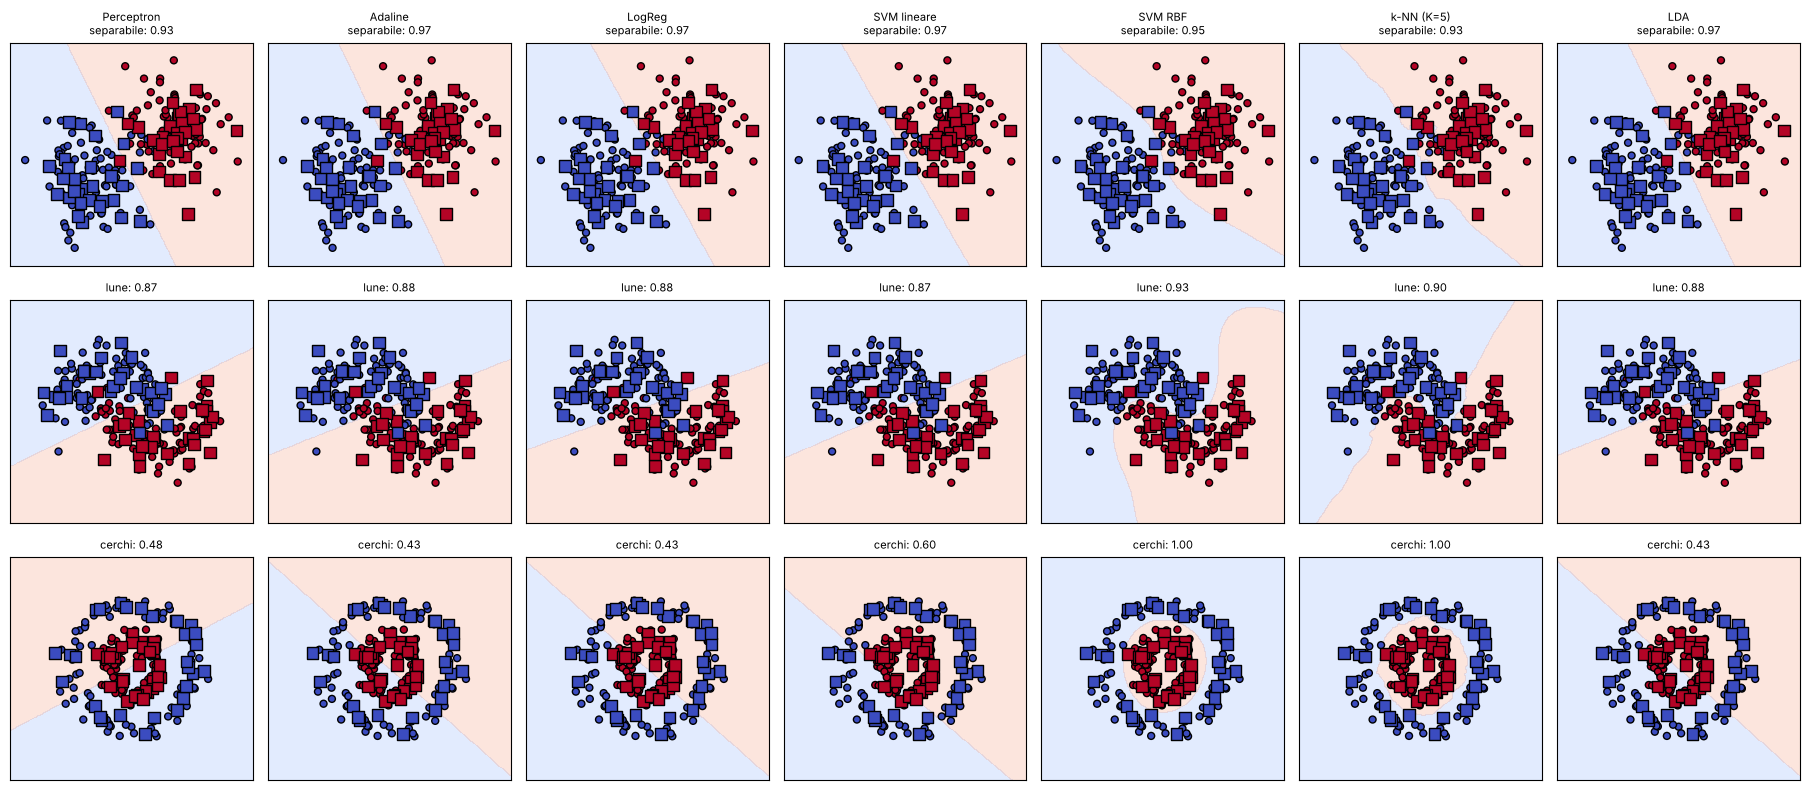

,separabile,lune,cerchi
Perceptron,0.93,0.87,0.48
Adaline,0.97,0.88,0.43
LogReg,0.97,0.88,0.43
SVM lineare,0.97,0.87,0.60
SVM RBF,0.95,0.93,1.00
k-NN (K=5),0.93,0.90,1.00
LDA,0.97,0.88,0.43


In [22]:
MODELLI = {
    "Perceptron": make_pipeline(StandardScaler(), Perceptron(random_state=0)),
    "Adaline": make_pipeline(StandardScaler(), AdalineCF()),
    "LogReg": make_pipeline(StandardScaler(), LogisticRegression()),
    "SVM lineare": make_pipeline(StandardScaler(), SVC(kernel="linear")),
    "SVM RBF": make_pipeline(StandardScaler(), SVC(kernel="rbf")),
    "k-NN (K=5)": make_pipeline(StandardScaler(), KNeighborsClassifier(5)),
    "LDA": make_pipeline(StandardScaler(), LinearDiscriminantAnalysis()),
}
fig, axs = plt.subplots(3, len(MODELLI), figsize=(2.6 * len(MODELLI), 8))
tab = {}
for j, (nm, mod) in enumerate(MODELLI.items()):
    for i, nome in enumerate(DATI):
        _, acc = disegna(axs[i, j], mod, nome, "")
        axs[i, j].set_title(f"{nm}\n{nome}: {acc:.2f}" if i == 0 else f"{nome}: {acc:.2f}", fontsize=8)
        tab.setdefault(nm, {})[nome] = acc
plt.tight_layout(); plt.show()
pd.DataFrame(tab).T.round(2)

**Attenzione a come leggere la tabella.** È **un solo split** di 60 punti di test: differenze di 0.02-0.03 **non sono significative**. Per decidere sul serio servono la cross-validation e la nested CV (nb 06, slide *Nested cross-validation*). Quello che deve restare in testa è la **forma dei confini**:

| Famiglia | Confine |
|---|---|
| Perceptron, Adaline, LogReg, SVM lineare, LDA | **retta** (ai cerchi non possono arrivare) |
| SVM RBF, k-NN | **curva** qualunque (rischio overfitting) |

### Le tue parole (1)
In una cella di testo qui sotto, spiega a un compagno di corso **perché Perceptron, Adaline e logistica hanno lo stesso confine "a retta" ma sono modelli diversi**.

*(scrivi qui la tua risposta)*

# Parte B. Riduzione delle dimensioni `[corso]` (nb 09 e slide *Dimensionality Reduction*, Papini)

Mappa della parte, nello stesso ordine delle slide:

| Blocco | Domanda a cui risponde |
|---|---|
| B0. Curse of dimensionality | **perché** troppe feature fanno male |
| B1. Feature selection (filter, wrapper, embedded) | **quali colonne** tengo tra quelle che ho |
| B2. Feature extraction: PCA | creo poche colonne nuove che tengono **la varianza** |
| B3. Kernel PCA | come la PCA, ma con struttura **curva** |
| B4. LDA | creo poche colonne nuove che **separano le classi** |

Nel template del progetto tutto questo è lo step `dim_reduction` (oppure si lascia `None`).

**Notazione delle slide**: $N$ esempi $\mathbf{x}_n\in\mathbb{R}^D$ con target $t_n$. Vogliamo $\mathbf{z}=g(\mathbf{x})\in\mathbb{R}^m$ con $m<D$ che tenga l'informazione **utile per il compito**.

## B0. La maledizione della dimensionalità (curse of dimensionality)

**Perché tante feature sono un problema** (slide *Dimensionality Reduction*):
- molte misure descrivono **la stessa variazione** (ridondanza);
- alcune feature portano **poca informazione** sul target;
- più feature = più **tempo e memoria**;
- a parità di dati, più feature possono portare a **overfitting** (il bias scende ma **la varianza cresce senza controllo**).

**Tre immagini dalle slide**
1. **L'arancia** (Pedro Domingos): un'arancia in $D$ dimensioni con buccia pari al 10% del raggio. La buccia vale $1-0.9^D$ del volume. In 10D è già il 65%: **in alta dimensione quasi tutto è buccia**, cioè i punti stanno "ai bordi", lontani tra loro.
2. **La griglia**: dividere ogni asse in 10 parti dà $10^D$ celle. Per riempirle tutte di dati servono esponenzialmente più esempi.
3. **Le feature polinomiali**: con $D=100$ variabili e grado 3 hai già 176.850 colonne.

**Effetti sui modelli** (slide):
- **k-NN**: i vicini non sono più vicini (vedi approfondimento k-NN), il bias cresce.
- **SVM RBF**: con $\gamma$ fisso, punti vicini in poche dimensioni diventano lontani in tante; meno punti contribuiscono a ogni predizione (più varianza). Allargare il raggio liscia via le strutture locali (più bias).

**Dimensione intrinseca**: il numero minimo di variabili che servono davvero a descrivere la soluzione. Trovarla sarebbe ideale, ma può essere difficile quanto risolvere il problema.

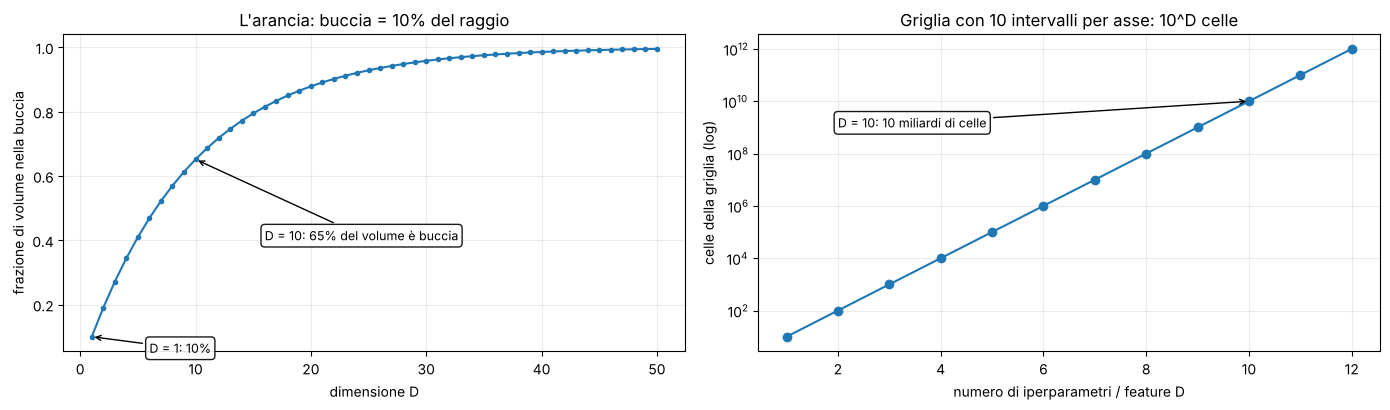

Numero di feature polinomiali (senza la colonna costante), come nella tabella delle slide:


,D = 2,D = 10,D = 100
grado 2,5,65,5150
grado 3,9,285,176850
grado 4,14,1000,4598125
grado 5,20,3002,96560645


In [23]:
from math import comb
Ds = np.arange(1, 51)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ax[0].plot(Ds, 1 - 0.9 ** Ds, "o-", ms=3); ax[0].set_xlabel("dimensione D"); ax[0].set_ylabel("frazione di volume nella buccia")
ax[0].set_title("L'arancia: buccia = 10% del raggio")
annota(ax[0], f"D = 10: {1 - .9 ** 10:.0%} del volume è buccia", (10, 1 - .9 ** 10), (16, .4))
annota(ax[0], "D = 1: 10%", (1, .1), (6, .05))
ax[1].semilogy(Ds[:12], 10.0 ** Ds[:12], "o-"); ax[1].set_xlabel("numero di iperparametri / feature D")
ax[1].set_ylabel("celle della griglia (log)"); ax[1].set_title("Griglia con 10 intervalli per asse: 10^D celle")
annota(ax[1], "D = 10: 10 miliardi di celle", (10, 1e10), (2, 1e9))
plt.tight_layout(); plt.show()

tab = pd.DataFrame({f"D = {D}": [comb(D + g, g) - 1 for g in [2, 3, 4, 5]] for D in [2, 10, 100]}, index=[f"grado {g}" for g in [2, 3, 4, 5]])
print("Numero di feature polinomiali (senza la colonna costante), come nella tabella delle slide:")
tab

## B1. Feature selection `[corso]`

**Cosa fa**: sceglie un **sottoinsieme** $S$ delle $D$ colonne originali, $|S|=m$. Le colonne scelte restano **identiche**, le altre si buttano. Vantaggio: resta **interpretabile** (sai quali misure contano).

Problema: i sottoinsiemi possibili sono $2^D$. Servono quindi due scelte:
1. una **regola di valutazione** (come dò il voto a una feature o a un sottoinsieme?);
2. una **strategia di ricerca** (quali sottoinsiemi provo?).

**Tre famiglie** (slide *Families of feature-selection methods*):

| Famiglia | Come valuta | Esempio | Pro | Contro |
|---|---|---|---|---|
| **Filter** | guarda i dati, **senza** allenare il modello finale | correlazione con il target, Fisher score, varianza | economico | non vede le interazioni tra feature |
| **Wrapper** | allena il modello su ogni sottoinsieme e misura la CV | forward selection con cross-validation | misura direttamente la performance | **costoso**; il risultato dipende dal modello scelto |
| **Embedded** | la selezione avviene **dentro** l'allenamento | **LASSO** (regolarizzazione L1) | niente ri-allenamenti per ogni sottoinsieme | $\lambda$ va comunque scelto con la validazione |

**LASSO** in breve: $\min_\mathbf{w} L(\mathbf{w})+\lambda\sum_j|w_j|$. A differenza di Ridge (L2, che rimpicciolisce i pesi), la penalità L1 **porta alcuni pesi esattamente a zero**: le feature con peso zero sono scartate.

**Strategie di ricerca** (per filter e wrapper): esaustiva (tutti i sottoinsiemi), **forward** (parti da vuoto, aggiungi la migliore), **backward** (parti da tutte, togli quella che fa meno danno), floating (aggiunge e toglie), randomizzata.

**Quando fermarsi**: nella curva "punteggio CV contro numero di feature" cerca il **gomito**: con la forward search è il punto dove la curva inizia a fare **plateau**.

I tre grafici sotto mostrano una tecnica per famiglia. Il dataset *wine* (13 feature, 3 classi) è scelto da me per avere conti veloci; il nb 09 usa le cifre.

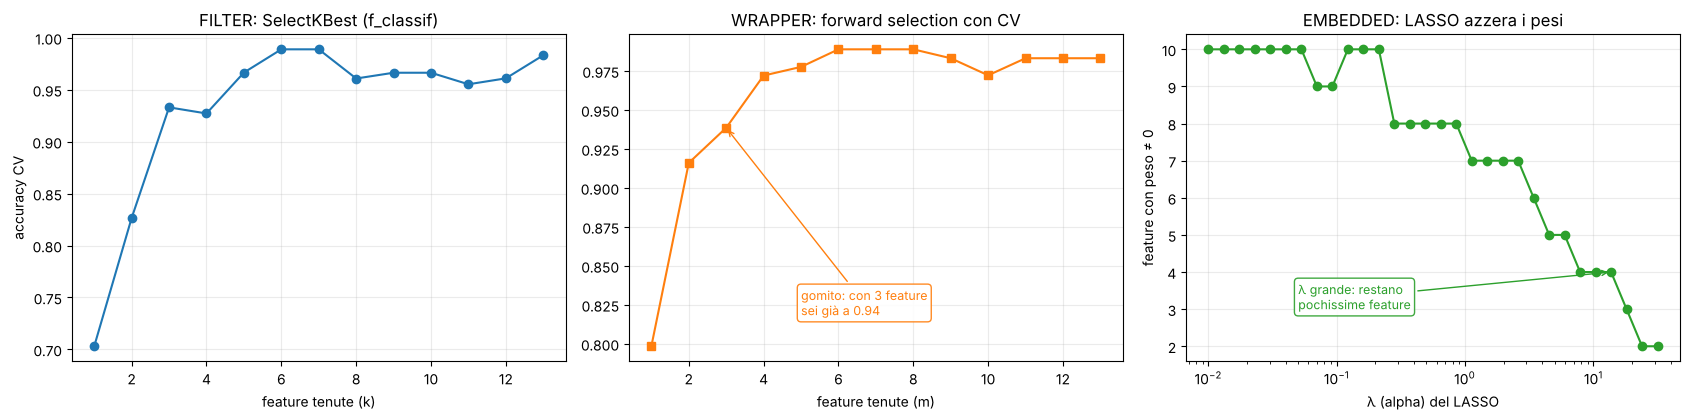

ordine di ingresso nella forward selection: ['flavanoids', 'alcohol', 'proline', 'hue'] ...


In [24]:
from sklearn.datasets import load_wine, load_diabetes
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import Lasso
Xw, yw = load_wine(return_X_y=True)
base = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))

# FILTER: punteggio individuale (ANOVA F, simile al Fisher score)
ks = range(1, 14)
filt = [cross_val_score(make_pipeline(StandardScaler(), SelectKBest(f_classif, k=k), LogisticRegression(max_iter=2000)), Xw, yw, cv=5).mean() for k in ks]

# WRAPPER: forward selection, a ogni passo aggiungo la feature che alza di più la CV
scelte, rimaste, fwd = [], list(range(13)), []
for _ in range(13):
    punteggi = {j: cross_val_score(base, Xw[:, scelte + [j]], yw, cv=5).mean() for j in rimaste}
    j_best = max(punteggi, key=punteggi.get); scelte.append(j_best); rimaste.remove(j_best); fwd.append(punteggi[j_best])

# EMBEDDED: LASSO su regressione (diabetes, 10 feature): quante feature restano con peso != 0
Xdb, ydb = load_diabetes(return_X_y=True); Xdb = StandardScaler().fit_transform(Xdb)
alphas = np.logspace(-2, 1.5, 30)
nz = [(Lasso(alpha=a, max_iter=10000).fit(Xdb, ydb).coef_ != 0).sum() for a in alphas]

fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
ax[0].plot(ks, filt, "o-"); ax[0].set_xlabel("feature tenute (k)"); ax[0].set_ylabel("accuracy CV"); ax[0].set_title("FILTER: SelectKBest (f_classif)")
ax[1].plot(ks, fwd, "s-", c="tab:orange"); ax[1].set_xlabel("feature tenute (m)"); ax[1].set_title("WRAPPER: forward selection con CV")
annota(ax[1], f"gomito: con 3 feature\nsei già a {fwd[2]:.2f}", (3, fwd[2]), (5, fwd[0] + .02), "tab:orange")
ax[2].semilogx(alphas, nz, "o-", c="tab:green"); ax[2].set_xlabel("λ (alpha) del LASSO"); ax[2].set_ylabel("feature con peso ≠ 0")
ax[2].set_title("EMBEDDED: LASSO azzera i pesi")
annota(ax[2], "λ grande: restano\npochissime feature", (alphas[-4], nz[-4]), (0.05, 3), "tab:green")
plt.tight_layout(); plt.show()
print("ordine di ingresso nella forward selection:", [load_wine().feature_names[j] for j in scelte[:4]], "...")

## B2-B4. Feature extraction: le tre schede in breve `[corso]`

Serve a due cose: **ridurre il rumore/costo** (meno colonne) e **visualizzare**. Nel template è lo step `dim_reduction`.

Distinzione chiave `[corso]`:
- **Feature selection**: scegli un sottoinsieme delle colonne esistenti (filter, wrapper).
- **Feature extraction**: crei **nuove** colonne combinando quelle vecchie (PCA, LDA, kernel PCA).

Dataset: le cifre scritte a mano di sklearn (64 pixel per immagine, 10 classi). Nota `[mio]`: nel notebook 09 il prof usa un altro dataset di cifre; questo è un dataset giocattolo per avere un grafico subito.

## B1. PCA `[corso]`
- **Idea**: trova le direzioni lungo cui i dati **variano di più** e li proietta lì.
- **Peculiarità**: **lineare** e **non supervisionata**: non guarda le etichette `[corso]`.
- **Forte**: veloce; `n_components` si può scegliere come "quanta varianza voglio tenere" (es. 0.95).
- **Debole**: la direzione di massima varianza **non è detto che separi le classi**. Solo trasformazioni lineari.
- **Manopole**: `n_components` (intero o frazione di varianza spiegata).

## B2. LDA come riduzione `[corso]`
- **Peculiarità**: **supervisionata**. Cerca le direzioni che separano le classi, non quelle di massima varianza.
- **Forte**: con poche componenti separa bene le classi.
- **Debole**: al massimo $C-1$ componenti. Lineare.

## B3. Kernel PCA `[corso]`
- **Peculiarità**: PCA **non lineare** (usa un kernel, come l'SVM). Utile quando la struttura è curva.
- **Debole**: è difficile misurare la varianza spiegata `[corso]`. Costa di più, ha manopole di kernel (`gamma`).

### Approfondimento B2: PCA passo per passo (slide *Principal Component Analysis*)

**Cosa vuol dire "componente principale"?** È una **nuova colonna**, combinazione lineare di quelle vecchie, costruita lungo la direzione in cui i dati **variano di più**. "Principale" perché le ordiniamo dalla più importante.

**I cinque passi** (slide *PCA*, p. 38):
1. **Centra** i dati: $\boldsymbol\mu=\frac1N\sum_n\mathbf{x}_n$, $\tilde{\mathbf{x}}_n=\mathbf{x}_n-\boldsymbol\mu$.
2. **Covarianza**: $C=\frac1N\sum_n\tilde{\mathbf{x}}_n\tilde{\mathbf{x}}_n^\top$, matrice $D\times D$. Sulla diagonale le varianze delle feature, fuori diagonale le covarianze tra coppie.
3. **Autovalori e autovettori** di $C$: $C\mathbf{u}_j=\lambda_j\mathbf{u}_j$, ordinati $\lambda_1\ge\lambda_2\ge\dots\ge0$. Gli autovettori $\mathbf{u}_j$ sono le **direzioni principali**, ortogonali tra loro.
4. Tieni i primi $m$ in $W=[\mathbf{u}_1,\dots,\mathbf{u}_m]$, matrice $D\times m$.
5. **Trasforma**: $\mathbf{z}(\mathbf{x})=W^\top(\mathbf{x}-\boldsymbol\mu)$. Le $z_j$ sono le **componenti principali**.

**Cosa significano gli autovalori**: $\lambda_j$ è **la varianza dei dati lungo $\mathbf{u}_j$** ("varianza spiegata"). Una direzione con $\lambda$ quasi zero è una direzione in cui i dati quasi non si muovono: buttarla costa poco.

**Quante componenti tenere**: la frazione di varianza spiegata è $\rho=\frac{\sum_{i\le m}\lambda_i}{\sum_{i\le D}\lambda_i}$. Regole pratiche: la più piccola $m$ con $\rho\ge95\%$, oppure il gomito dello **scree plot**, oppure la cross-validation (nel template: `n_components` nella griglia).

**Un altro modo di vederla**: la PCA trova il sottospazio di dimensione $m$ che **ricostruisce** meglio i dati (errore quadratico minimo), e l'errore di ricostruzione è esattamente la varianza scartata $\sum_{j>m}\lambda_j$.

**Esempio a mano, con numeri miei** (la slide p. 39 ha un esercizio analogo con altri numeri: quello lo fai tu).
Sia $\boldsymbol\mu=(0,0)$ e $C=\begin{pmatrix}2&1\\1&2\end{pmatrix}$.
- Autovalori: $\lambda_1=3$, $\lambda_2=1$. Autovettori: $\mathbf{u}_1=\frac{1}{\sqrt2}(1,1)$, $\mathbf{u}_2=\frac{1}{\sqrt2}(1,-1)$.
- Tenendo solo $\mathbf{u}_1$ resta $\rho=3/(3+1)=75\%$ della varianza.
- Per $\mathbf{x}=(2,0)$: $z_1=\mathbf{u}_1^\top\mathbf{x}=2/\sqrt2\approx1.41$.

La cella sotto verifica questi numeri con numpy e mostra le direzioni e la ricostruzione delle cifre.

**Limiti** (slide *Limits of PCA*): è **lineare** (per strutture curve servono tante componenti) ed è **non supervisionata**: può buttare una direzione con poca varianza che però era proprio quella utile a separare le classi.

autovalori: [3. 1.] | u1 = [0.707 0.707] | varianza tenuta con m=1: 0.75
z1 per x=(2,0): 1.414


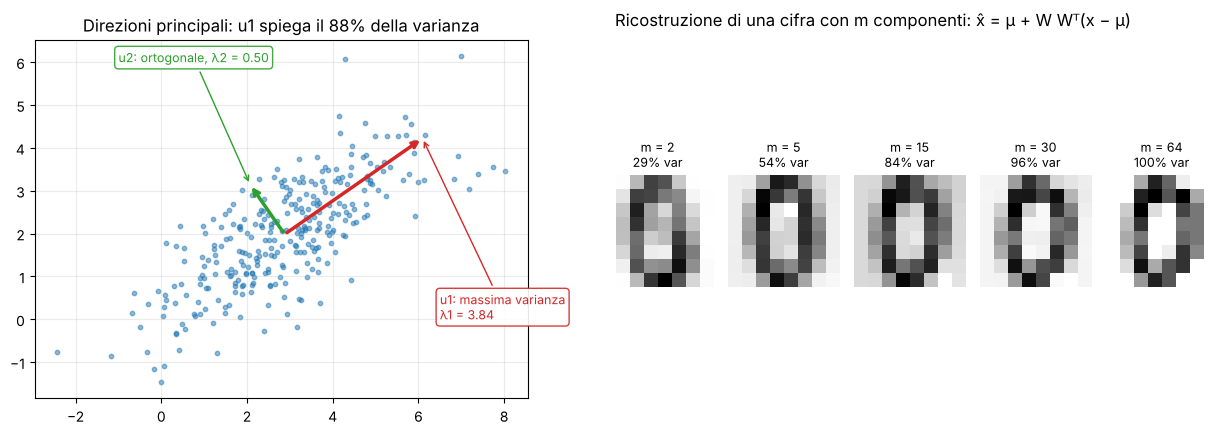

In [25]:
Cm = np.array([[2., 1.], [1., 2.]])
lam, U = np.linalg.eigh(Cm); ordine = np.argsort(lam)[::-1]; lam, U = lam[ordine], U[:, ordine]
print("autovalori:", lam, "| u1 =", U[:, 0].round(3), "| varianza tenuta con m=1:", lam[0] / lam.sum())
print("z1 per x=(2,0):", round(abs(U[:, 0] @ np.array([2, 0])), 3))

rng = np.random.RandomState(1)
Xp = rng.multivariate_normal([3, 2], [[3, 1.6], [1.6, 1.5]], 300)
pca = PCA().fit(Xp); mu = pca.mean_
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ax[0].scatter(*Xp.T, s=10, alpha=.5)
for j, c in enumerate(["tab:red", "tab:green"]):
    v = pca.components_[j] * 2 * np.sqrt(pca.explained_variance_[j])
    ax[0].annotate("", xy=mu + v, xytext=mu, arrowprops=dict(arrowstyle="->", lw=2.5, color=c))
annota(ax[0], f"u1: massima varianza\nλ1 = {pca.explained_variance_[0]:.2f}", tuple(mu + pca.components_[0] * 2 * np.sqrt(pca.explained_variance_[0])), (6.5, 0), "tab:red")
annota(ax[0], f"u2: ortogonale, λ2 = {pca.explained_variance_[1]:.2f}", tuple(mu + pca.components_[1] * 2 * np.sqrt(pca.explained_variance_[1])), (-1, 6), "tab:green")
ax[0].set_aspect("equal"); ax[0].set_title(f"Direzioni principali: u1 spiega il {pca.explained_variance_ratio_[0]:.0%} della varianza")

dg2 = load_digits(); Xd2 = dg2.data; img = Xd2[0]
ax[1].axis("off"); ax[1].set_title("Ricostruzione di una cifra con m componenti: x̂ = μ + W Wᵀ(x − μ)")
for k, m in enumerate([2, 5, 15, 30, 64]):
    p = PCA(n_components=m).fit(Xd2); rec = p.inverse_transform(p.transform(img[None]))[0]
    sub = fig.add_axes([0.53 + k * 0.09, 0.22, 0.08, 0.5]); sub.imshow(rec.reshape(8, 8), cmap="gray_r")
    sub.set_title(f"m = {m}\n{p.explained_variance_ratio_.sum():.0%} var", fontsize=9); sub.axis("off")
plt.show()

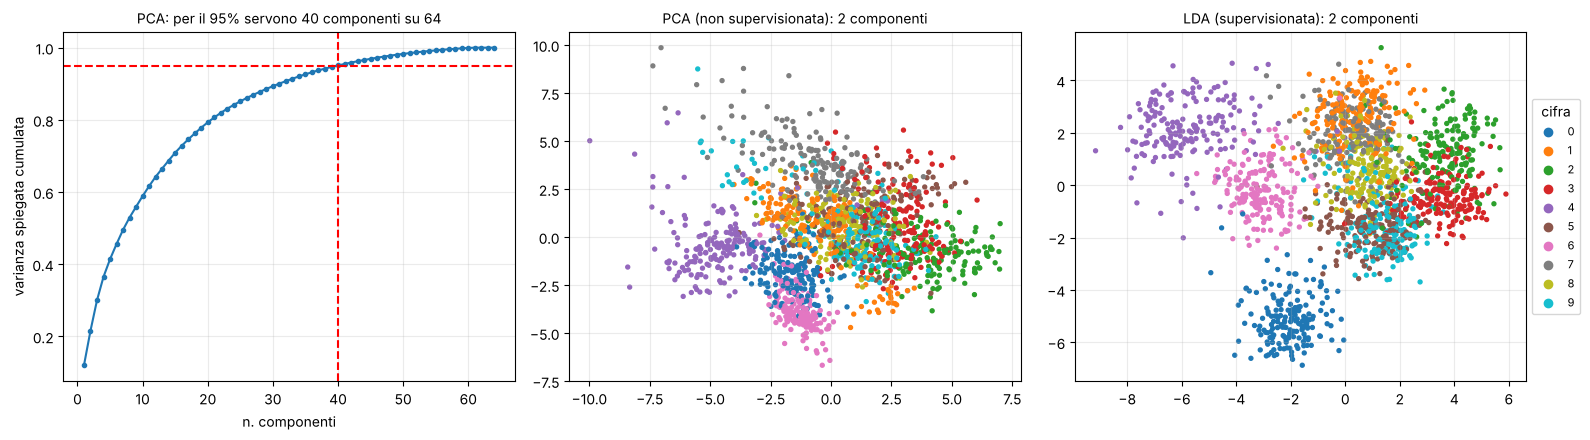

In [26]:
dg = load_digits()
Xd, yd = dg.data, dg.target
Xd = StandardScaler().fit_transform(Xd)

p = PCA().fit(Xd)
cum = np.cumsum(p.explained_variance_ratio_)
k95 = int(np.searchsorted(cum, 0.95) + 1)

pca2 = PCA(n_components=2).fit_transform(Xd)
lda2 = LinearDiscriminantAnalysis(n_components=2).fit(Xd, yd).transform(Xd)

fig, axs = plt.subplots(1, 3, figsize=(16, 4.5))
axs[0].plot(range(1, 65), cum, "o-", ms=3); axs[0].axhline(.95, color="r", ls="--"); axs[0].axvline(k95, color="r", ls="--")
axs[0].set_xlabel("n. componenti"); axs[0].set_ylabel("varianza spiegata cumulata")
axs[0].set_title(f"PCA: per il 95% servono {k95} componenti su 64", fontsize=10)
for a, Z, t in [(axs[1], pca2, "PCA (non supervisionata): 2 componenti"), (axs[2], lda2, "LDA (supervisionata): 2 componenti")]:
    sc = a.scatter(*Z.T, c=yd, cmap="tab10", s=8); a.set_title(t, fontsize=10)
axs[2].legend(*sc.legend_elements(), loc="center left", bbox_to_anchor=(1, .5), title="cifra", fontsize=8)
plt.tight_layout(); plt.show()

**Cosa guardare.** Con le stesse 2 componenti la LDA tiene alcune cifre **più separate** (ad esempio 0, 4 e 6 formano gruppi netti), perché ha visto le etichette. La PCA, che non le ha viste, le mescola di più. Con 2 sole componenti nessuna delle due separa tutte le 10 cifre.

Attenzione però: in questo grafico LDA è stata allenata su **tutti** i dati, solo per disegnare. Nei veri esperimenti la riduzione va **dentro la pipeline**, allenata solo sul training (altrimenti c'è **data leakage**, domanda ancora aperta del template sull'imputazione).

In [27]:
Xtr, Xte, ytr, yte = train_test_split(dg.data, dg.target, test_size=.3, stratify=dg.target, random_state=0)
cand = {
    "dummy": DummyClassifier(strategy="most_frequent"),
    "LogReg su 64 pixel": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    f"PCA(95%) + LogReg": make_pipeline(StandardScaler(), PCA(n_components=.95), LogisticRegression(max_iter=2000)),
    "LDA(9) + LogReg": make_pipeline(StandardScaler(), LinearDiscriminantAnalysis(n_components=9), LogisticRegression(max_iter=2000)),
}
righe = []
for nm, mod in cand.items():
    cv = cross_val_score(mod, Xtr, ytr, cv=5).mean()
    righe.append((nm, round(cv, 3), round(mod.fit(Xtr, ytr).score(Xte, yte), 3)))
pd.DataFrame(righe, columns=["pipeline", "acc CV (train)", "acc test"]).set_index("pipeline")

,acc CV (train),acc test
pipeline,,
dummy,0.101,0.102
LogReg su 64 pixel,0.964,0.972
PCA(95%) + LogReg,0.957,0.967
LDA(9) + LogReg,0.948,0.950


**Cosa guardare.** Il dummy fa circa 0.1 (10 classi). Le tre pipeline reali stanno tutte molto sopra. Ridurre le dimensioni non è per forza "più accurato": spesso serve per **ridurre la complessità** mantenendo la performance. È una scelta da fare con la CV, non a occhio.

### Approfondimento B4: LDA come riduzione (slide *Linear Discriminant Analysis*, nb 09)

**L'idea**: cercare la direzione $\mathbf{w}$ lungo cui, proiettando, **i centri delle classi sono lontani** e **ogni classe è stretta**.

**Fisher's criterion (due classi)**:
$$J(\mathbf{w})=\frac{\big(\mathbf{w}^\top(\boldsymbol\mu_1-\boldsymbol\mu_2)\big)^2}{\mathbf{w}^\top S_W\mathbf{w}}$$
- Numeratore: **distanza tra i centri** dopo la proiezione, al quadrato.
- Denominatore: **larghezza delle classi** lungo $\mathbf{w}$. $S_W=\sum_c\sum_{n:t_n=c}(\mathbf{x}_n-\boldsymbol\mu_c)(\mathbf{x}_n-\boldsymbol\mu_c)^\top$ è la *within-class scatter*.

Nel nb 09 il denominatore è scritto $N_0\,\mathbf{w}^\top S_0\mathbf{w}+N_1\,\mathbf{w}^\top S_1\mathbf{w}$: è la stessa cosa, perché $N_c S_c$ è proprio lo scatter della classe $c$.

**La soluzione ha una formula** (slide *The two-class LDA direction*):
$$\mathbf{w}\propto S_W^{-1}(\boldsymbol\mu_1-\boldsymbol\mu_2)$$
- $\boldsymbol\mu_1-\boldsymbol\mu_2$ è la direzione che unisce i centri;
- $S_W^{-1}$ la **corregge** tenendo conto della forma (inclinazione) delle nuvole. Per questo la direzione LDA non è quella che unisce i centri.
- Se $S_W$ è quasi singolare si regolarizza: $S_W+\delta I$ (come Ridge).

**Più classi**: si aggiunge la *between-class scatter* $S_B=\sum_c N_c(\boldsymbol\mu_c-\boldsymbol\mu)(\boldsymbol\mu_c-\boldsymbol\mu)^\top$ e si massimizza $\frac{\mathbf{w}^\top S_B\mathbf{w}}{\mathbf{w}^\top S_W\mathbf{w}}$. Si ottengono al massimo $\min\{D,\,C-1\}$ direzioni (un *generalized eigenproblem*). Con 10 cifre: al massimo 9 componenti, ed è per questo che il nb 09 usa `n_components=9`.

Nota: nel testo che ho estratto dalla slide p. 53 la media $\boldsymbol\mu_c$ è scritta senza $\frac{1}{N_c}$; nel nb 09 c'è. Controlla sulla slide: credo sia un refuso.

**PCA contro LDA, la figura chiave** (slide *PCA vs LDA*): sotto, due classi allungate e parallele. La PCA sceglie la direzione di **massima varianza totale**, che corre lungo le nuvole e le **mescola**. La LDA sceglie quella che le **separa**.

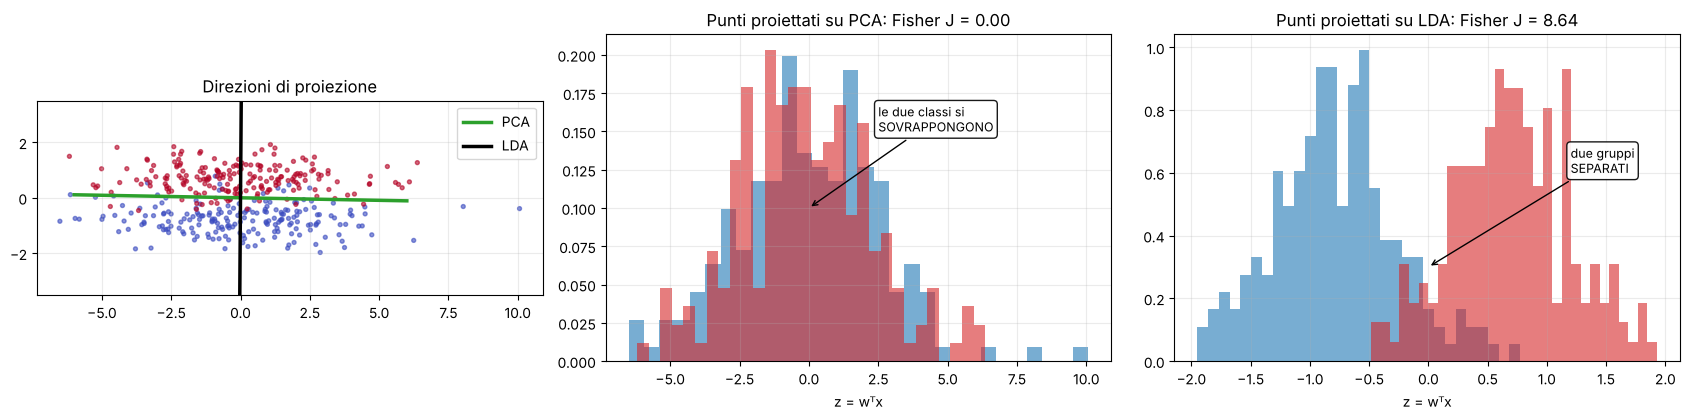

direzione PCA: [ 1.   -0.02] | direzione LDA: [0.01 1.  ]


In [28]:
rng = np.random.RandomState(2)
cov = [[6, 0], [0, 0.25]]
X0 = rng.multivariate_normal([0, -0.8], cov, 200); X1 = rng.multivariate_normal([0, 0.8], cov, 200)
Xpl = np.r_[X0, X1]; ypl = np.r_[np.zeros(200), np.ones(200)]
w_pca = PCA(1).fit(Xpl).components_[0]
mu0, mu1 = X0.mean(0), X1.mean(0)
SW = (X0 - mu0).T @ (X0 - mu0) + (X1 - mu1).T @ (X1 - mu1)
w_lda = np.linalg.solve(SW, mu1 - mu0); w_lda /= np.linalg.norm(w_lda)
J = lambda w: (w @ (mu1 - mu0)) ** 2 / (w @ (SW / len(Xpl)) @ w)   # S_W diviso per N: stessa direzione, numeri leggibili

fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
ax[0].scatter(*Xpl.T, c=ypl, cmap=CMAP, s=8, alpha=.6)
for w, c, nm in [(w_pca, "tab:green", "PCA"), (w_lda, "k", "LDA")]:
    ax[0].plot([-6 * w[0], 6 * w[0]], [-6 * w[1], 6 * w[1]], c=c, lw=2.5, label=nm)
ax[0].set_aspect("equal"); ax[0].set_ylim(-3.5, 3.5); ax[0].legend(); ax[0].set_title("Direzioni di proiezione")
for a, w, nm in [(ax[1], w_pca, "PCA"), (ax[2], w_lda, "LDA")]:
    z = Xpl @ w
    a.hist(z[ypl == 0], 30, alpha=.6, color="tab:blue", density=True); a.hist(z[ypl == 1], 30, alpha=.6, color="tab:red", density=True)
    a.set_title(f"Punti proiettati su {nm}: Fisher J = {J(w):.2f}"); a.set_xlabel("z = wᵀx")
annota(ax[1], "le due classi si\nSOVRAPPONGONO", (0, .1), (2.5, .15))
annota(ax[2], "due gruppi\nSEPARATI", (0, .3), (1.2, .6))
plt.tight_layout(); plt.show()
print("direzione PCA:", w_pca.round(2), "| direzione LDA:", w_lda.round(2))

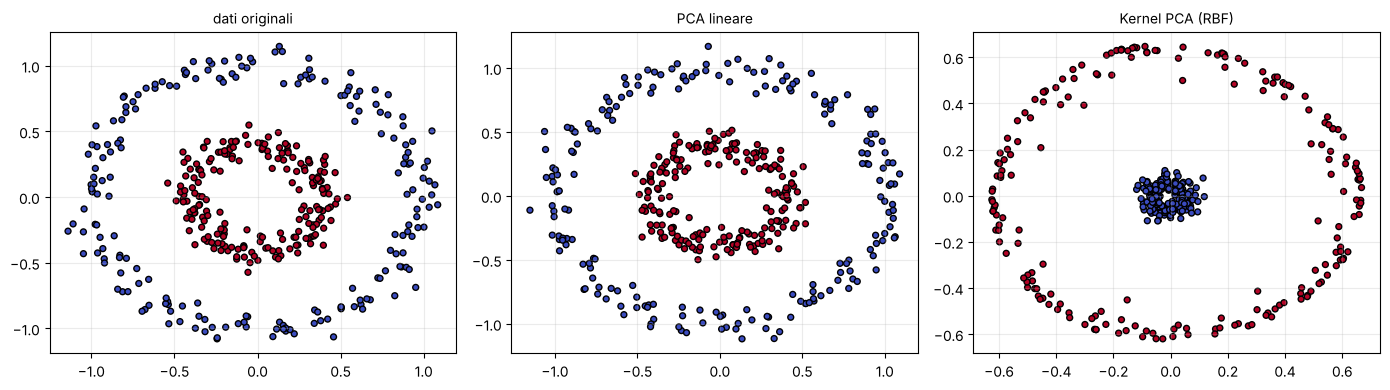

In [29]:
Xc, yc = make_circles(400, noise=0.07, factor=0.4, random_state=0)
Zl = PCA(n_components=2).fit_transform(Xc)
Zk = KernelPCA(n_components=2, kernel="rbf", gamma=8).fit_transform(Xc)
fig, axs = plt.subplots(1, 3, figsize=(14, 4))
for a, Z, t in [(axs[0], Xc, "dati originali"), (axs[1], Zl, "PCA lineare"), (axs[2], Zk, "Kernel PCA (RBF)")]:
    a.scatter(*Z.T, c=yc, cmap=CMAP, edgecolor="k", s=18); a.set_title(t, fontsize=10)
plt.tight_layout(); plt.show()

**Cosa guardare.** La PCA lineare è solo una **rotazione**: i cerchi restano uno dentro l'altro. La Kernel PCA cambia davvero la struttura (qui "rovescia" i cerchi: quello esterno finisce schiacciato al centro), ma in queste **2** componenti le classi **non** sono ancora separabili da una retta. *Correzione rispetto a ieri: avevo scritto il contrario.* Nell'approfondimento B3 vedi che serve la terza componente. È lo stesso trucco del kernel nella SVM, applicato alla PCA.

### Le tue parole (2)
Spiega a un compagno **perché la PCA può *non* aiutare un classificatore** mentre la LDA di solito aiuta (pensa a "varianza" contro "separazione tra classi").

### Approfondimento B3: Kernel PCA (slide *Kernel PCA*)

**Idea**: fare la PCA nello spazio delle feature $\phi(\mathbf{x})$ di un kernel, senza costruirlo (kernel trick, come nella SVM).

**Come si calcola, a grandi linee** (slide pp. 44-48):
1. Costruisci la **matrice di Gram** $K_{nm}=k(\mathbf{x}_n,\mathbf{x}_m)$, grande $N\times N$.
2. **Centrala**: $\bar K = HKH$ con $H=I_N-\frac1N\mathbf{1}\mathbf{1}^\top$. Serve perché centrare gli input non centra le feature.
3. Trova autovalori $\eta_1\ge\dots$ e autovettori $\mathbf{v}_j$ di $\bar K$, tieni i primi $m$.
4. Le componenti dei punti di training sono $\mathbf{z}_j=\sqrt{\eta_j}\,\mathbf{v}_j$.
5. Per un punto nuovo servono le somiglianze con **tutti** i punti di training.

**Limiti**: serve memorizzare una matrice $N\times N$ e la scomposizione costa $O(N^3)$; trasformare un punto nuovo richiede il confronto con tutto il training; ed è ancora **non supervisionata**. In più non c'è un modo semplice per misurare la varianza spiegata (nb 09): `n_components` e `gamma` si scelgono con la CV.

**Una lezione dal grafico sotto.** Sui cerchi, con $\gamma=2$, le prime due componenti **non** separano le classi. È la **terza** a separarle, da sola. La kernel PCA ordina le componenti per varianza, non per utilità per il compito: è proprio il limite "non supervisionata". Per questo `n_components` va scelto con la cross-validation (terzo pannello).

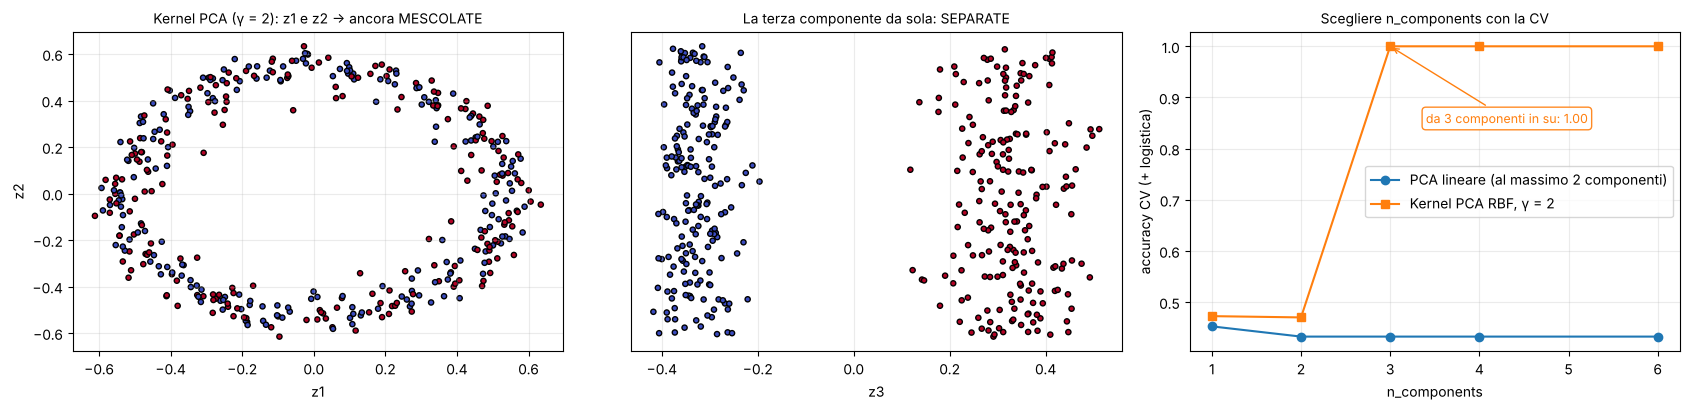

In [30]:
Xc3, yc3 = make_circles(400, noise=0.07, factor=0.4, random_state=0)
Z3 = KernelPCA(n_components=3, kernel="rbf", gamma=2).fit_transform(Xc3)
ms = [1, 2, 3, 4, 6]
acc_k = [cross_val_score(make_pipeline(KernelPCA(m, kernel="rbf", gamma=2), StandardScaler(), LogisticRegression()), Xc3, yc3, cv=5).mean() for m in ms]
acc_l = [cross_val_score(make_pipeline(PCA(min(m, 2)), LogisticRegression()), Xc3, yc3, cv=5).mean() for m in ms]
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
ax[0].scatter(Z3[:, 0], Z3[:, 1], c=yc3, cmap=CMAP, edgecolor="k", s=14); ax[0].set_xlabel("z1"); ax[0].set_ylabel("z2")
ax[0].set_title("Kernel PCA (γ = 2): z1 e z2 → ancora MESCOLATE", fontsize=10)
ax[1].scatter(Z3[:, 2], np.random.RandomState(0).uniform(-1, 1, len(yc3)), c=yc3, cmap=CMAP, edgecolor="k", s=14)
ax[1].set_xlabel("z3"); ax[1].set_yticks([]); ax[1].set_title("La terza componente da sola: SEPARATE", fontsize=10)
ax[2].plot(ms, acc_l, "o-", label="PCA lineare (al massimo 2 componenti)"); ax[2].plot(ms, acc_k, "s-", label="Kernel PCA RBF, γ = 2")
ax[2].set_xlabel("n_components"); ax[2].set_ylabel("accuracy CV (+ logistica)"); ax[2].legend(loc="center right"); ax[2].set_title("Scegliere n_components con la CV", fontsize=10)
annota(ax[2], "da 3 componenti in su: 1.00", (3, acc_k[2]), (3.4, .85), "tab:orange")
plt.tight_layout(); plt.show()

*(scrivi qui la tua risposta)*

# Parte C. Regressione `[corso]` (nb 05 e slide)

Qui la risposta è un **numero**, non una classe. La domanda di fondo non cambia: *quanto complesso deve essere il modello?*

## C1. Regressione lineare (OLS)
- **Idea**: la retta $\hat t = \mathbf{w}^\top\mathbf{x}$ che minimizza la somma degli errori al quadrato (RSS).
- **Peculiarità**: ha una **soluzione chiusa** (pseudo-inversa) oppure si usa gradient descent. È lo stesso Adaline, ma su valori continui.
- **Forte**: semplice, interpretabile.
- **Debole**: se la relazione è curva fa **underfitting**; con feature collineari o più feature che campioni la matrice non è invertibile (**rank deficiency**).

## C2. Ridge (regolarizzazione L2) `[corso]`
- **Peculiarità**: aggiunge $\lambda\|\mathbf{w}\|^2$ alla loss: penalizza pesi grandi. $\lambda I+\Phi^\top\Phi$ è **sempre invertibile**.
- **Forte**: argina l'overfitting, risolve la rank deficiency.
- **Manopole**: `alpha` ($\lambda$): grande = pesi piccoli, modello più semplice.

## C3. Polinomi: non è un modello, è un trucco
`PolynomialFeatures` aggiunge $x^2, x^3,\dots$ come **nuove colonne**; il modello resta una regressione **lineare nei pesi**. Il grado è un iperparametro di complessità.

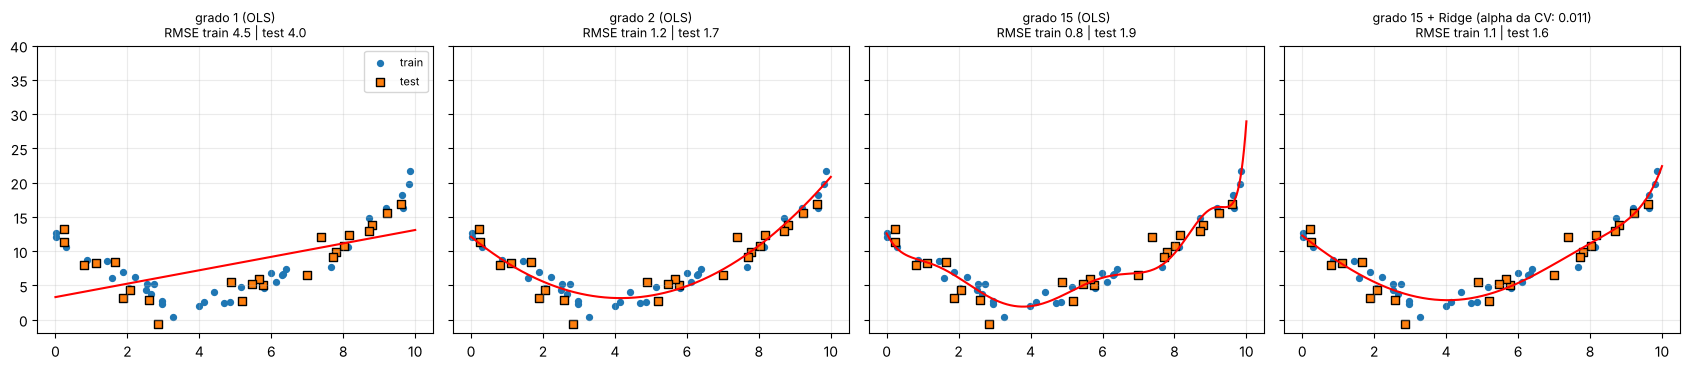

In [31]:
rng = np.random.RandomState(5)
x = rng.uniform(0, 10, 60)
t = 3 + 0.5 * (x - 4) ** 2 + rng.normal(0, 1.5, 60)
Xr = x.reshape(-1, 1)
Xrtr, Xrte, trtr, trte = train_test_split(Xr, t, test_size=.4, random_state=0)
xg = np.linspace(0, 10, 300).reshape(-1, 1)

mods = {
    "grado 1 (OLS)": make_pipeline(StandardScaler(), LinearRegression()),
    "grado 2 (OLS)": make_pipeline(PolynomialFeatures(2, include_bias=False), StandardScaler(), LinearRegression()),
    "grado 15 (OLS)": make_pipeline(PolynomialFeatures(15, include_bias=False), StandardScaler(), LinearRegression()),
    "grado 15 + Ridge": make_pipeline(PolynomialFeatures(15, include_bias=False), StandardScaler(), RidgeCV(alphas=np.logspace(-3, 2, 20), cv=5)),
}
fig, axs = plt.subplots(1, 4, figsize=(17, 3.8), sharey=True)
rmse = lambda a, b: float(np.sqrt(mean_squared_error(a, b)))
for a, (nm, mod) in zip(axs, mods.items()):
    mod.fit(Xrtr, trtr)
    a.scatter(Xrtr, trtr, s=18, label="train"); a.scatter(Xrte, trte, s=40, marker="s", edgecolor="k", label="test")
    a.plot(xg, mod.predict(xg), "r"); a.set_ylim(-2, 40)
    extra = f" (alpha da CV: {mod[-1].alpha_:.2g})" if "Ridge" in nm else ""
    a.set_title(f"{nm}{extra}\nRMSE train {rmse(trtr, mod.predict(Xrtr)):.1f} | test {rmse(trte, mod.predict(Xrte)):.1f}", fontsize=9)
axs[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Cosa guardare.** Grado 1: errore alto su train **e** test (underfitting, *bias alto*). Grado 2: giusto, perché i dati vengono da una parabola. Grado 15: l'errore di train scende ancora, ma il test **non migliora** rispetto al grado 2, e la curva oscilla e "esplode" vicino a x=10 (overfitting, *varianza alta*). Grado 15 con Ridge: `alpha` è scelto con la cross-validation **sul solo training** e la curva torna liscia; guarda i numeri nel titolo per vedere cosa succede a train e test.

Nota: il test ha pochi punti (24), quindi guarda la **forma** delle curve più dei decimali. E ricordati: `alpha` va scelto con la CV, **mai guardando il test**.

### Approfondimento: valutare una regressione (nb 05, nb 06, slide model selection)

**RMSE**: $\sqrt{\frac1N\sum_n(t_n-\hat t_n)^2}$, nella stessa unità del target ("sbaglio in media di circa X").

**R²** (slide *model selection*): $R^2=1-\frac{RSS}{TSS}$, con $RSS=\sum_n(t_n-\hat t_n)^2$ e $TSS=\sum_n(t_n-\bar t)^2$.
- È un confronto con il **modello banale che predice sempre la media** $\bar t$ (il "dummy" della regressione). `r2_score(y_test, y_pred)` calcola la media al suo interno.
- $R^2=1$: perfetto. $R^2=0$: come la media. $R^2<0$: **peggio** della media.

**Residual plot** (nb 05): sull'asse x la predizione, sull'asse y il residuo $t-\hat t$. Se il modello è giusto i punti sono una nuvola casuale attorno a 0. Se vedi una **forma** (per esempio una U), il modello sta mancando una struttura: tipicamente serve un termine non lineare.

**k-NN regression** (nb 05, slide *Nearest-neighbor regression*): $\hat t(\mathbf{x})=\frac1K\sum_{n\in N_K(\mathbf{x})}t_n$, la media dei target dei vicini. Con `weights='distance'` è una media pesata. $K=1$ insegue ogni punto, $K$ grande appiattisce la curva.

Esistono anche **kernel ridge regression** e la **media pesata gaussiana** (Nadaraya-Watson) nelle slide sui kernel: stessa idea della media dei vicini, ma pesata con un kernel.

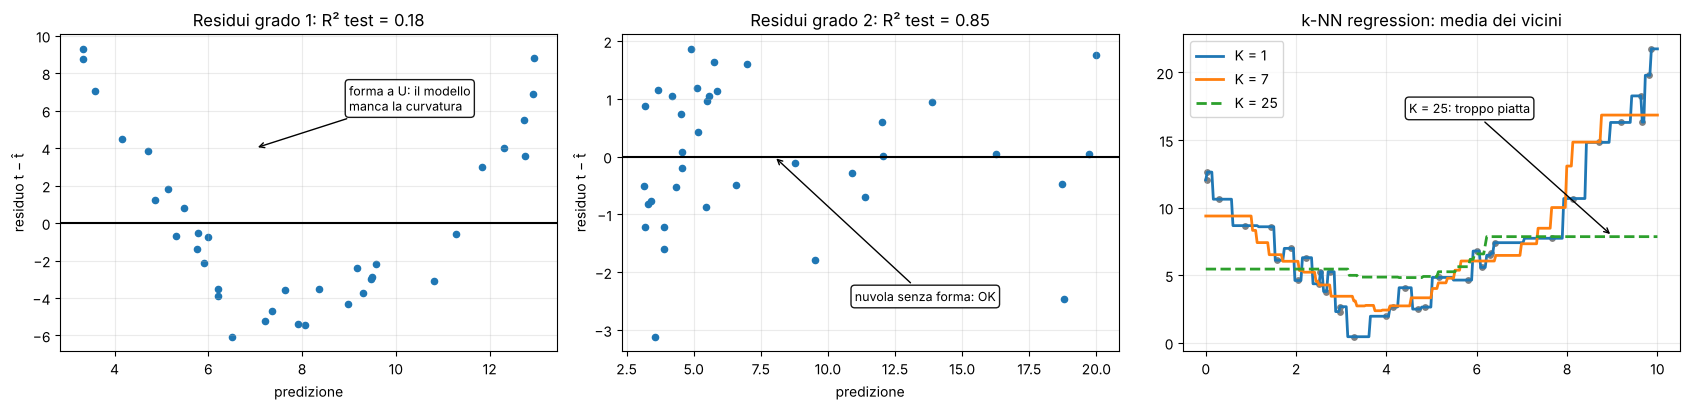

In [32]:
from sklearn.metrics import r2_score
from sklearn.neighbors import KNeighborsRegressor
m1 = make_pipeline(StandardScaler(), LinearRegression()).fit(Xrtr, trtr)
m2 = make_pipeline(PolynomialFeatures(2, include_bias=False), StandardScaler(), LinearRegression()).fit(Xrtr, trtr)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
for a, m, nm in [(ax[0], m1, "grado 1"), (ax[1], m2, "grado 2")]:
    pr = m.predict(Xrtr); a.scatter(pr, trtr - pr, s=20); a.axhline(0, c="k")
    a.set_xlabel("predizione"); a.set_ylabel("residuo t − t̂")
    a.set_title(f"Residui {nm}: R² test = {r2_score(trte, m.predict(Xrte)):.2f}")
annota(ax[0], "forma a U: il modello\nmanca la curvatura", (7, 4), (9, 6))
annota(ax[1], "nuvola senza forma: OK", (8, 0), (11, -2.5))
for K, st in [(1, "-"), (7, "-"), (25, "--")]:
    ax[2].plot(xg, KNeighborsRegressor(K).fit(Xrtr, trtr).predict(xg), st, lw=2, label=f"K = {K}")
ax[2].scatter(Xrtr, trtr, s=15, c="gray"); ax[2].legend(); ax[2].set_title("k-NN regression: media dei vicini")
annota(ax[2], "K = 25: troppo piatta", (9, 7.9), (4.5, 17))
plt.tight_layout(); plt.show()

# Parte D0. Misurare un classificatore `[corso]` (nb 06, slide *model selection*)

**Confusion matrix** (due classi, "positivo" = la classe che ti interessa trovare):

| | predetto positivo | predetto negativo |
|---|---|---|
| **vero positivo** | **TP** (preso!) | **FN** (mancato) |
| **vero negativo** | **FP** (falso allarme) | **TN** (ok) |

- **Accuracy** $=\frac{TP+TN}{\text{tutti}}$: inganna con classi sbilanciate.
- **Precision** $=\frac{TP}{TP+FP}$: "quando dico positivo, quante volte ho ragione?"
- **Recall** $=\frac{TP}{TP+FN}$: "dei positivi veri, quanti ne trovo?"
- **F1** $=2\frac{P\cdot R}{P+R}$: media armonica, alta solo se **entrambe** sono alte. È la metrica del template.

In sklearn: `precision_score(y_true, y_pred, pos_label=1)` e simili; `confusion_matrix(y_true, y_pred)`.

**Curva precision-recall** (nb 06): spostando la soglia del classificatore ottieni tante coppie (P, R). Si usa quando le classi sono sbilanciate.

**Classi sbilanciate** (nb 06, *Unbalanced classes*): con il 90% di negativi, il dummy fa accuracy 0.90 e F1 = 0. Rimedi: guardare F1 o la curva PR invece dell'accuracy, `stratify=y` nello split, `class_weight='balanced'` (pesa di più gli errori sulla classe rara), oppure un **sampler** (nel template: `imbalanced-learn`).

**Holdout contro K-fold** (nb 06): l'holdout usa **un** validation set (veloce, ma il risultato dipende dallo split); la K-fold ripete $K$ volte con fold diversi e fa la media (più stabile). Il test set si usa **una volta sola**, alla fine.

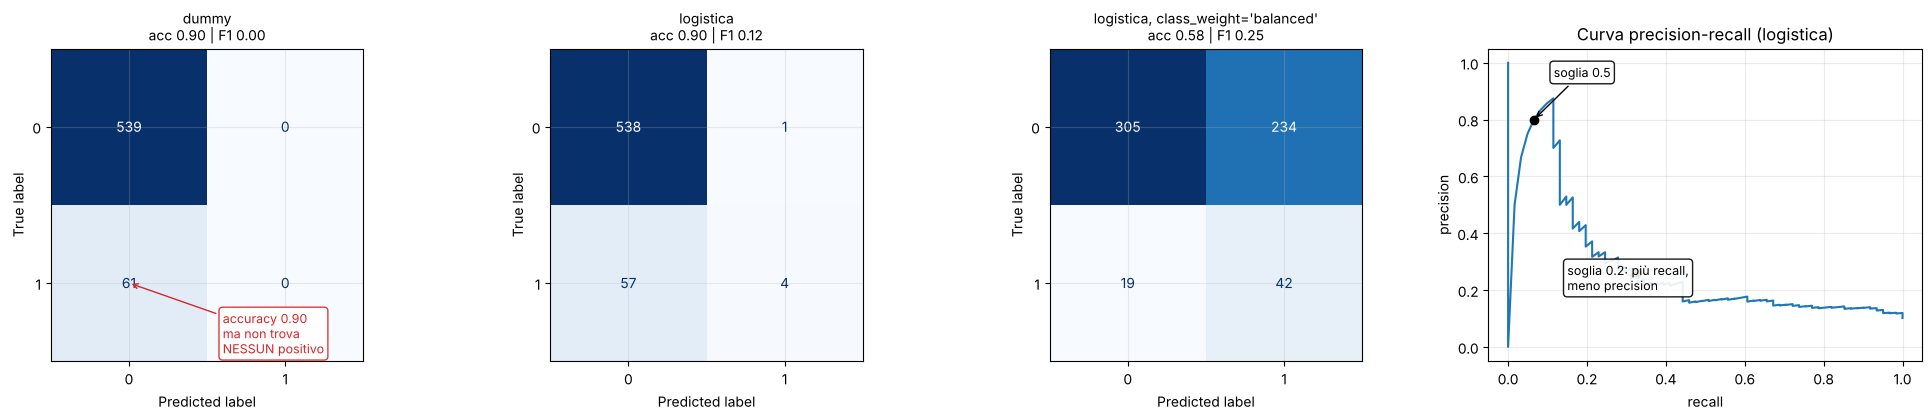

In [33]:
from sklearn.datasets import make_classification
from sklearn.metrics import ConfusionMatrixDisplay, f1_score, precision_recall_curve, accuracy_score
Xu, yu = make_classification(2000, n_features=6, n_informative=3, weights=[0.9, 0.1], class_sep=0.8, random_state=0)
Xutr, Xute, yutr, yute = train_test_split(Xu, yu, test_size=.3, stratify=yu, random_state=0)
mods = {"dummy": DummyClassifier(strategy="most_frequent"),
        "logistica": make_pipeline(StandardScaler(), LogisticRegression()),
        "logistica, class_weight='balanced'": make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced"))}
fig, ax = plt.subplots(1, 4, figsize=(20, 4.3))
for a, (nm, m) in zip(ax, mods.items()):
    pr = m.fit(Xutr, yutr).predict(Xute)
    ConfusionMatrixDisplay.from_predictions(yute, pr, ax=a, colorbar=False, cmap="Blues")
    a.set_title(f"{nm}\nacc {accuracy_score(yute, pr):.2f} | F1 {f1_score(yute, pr, zero_division=0):.2f}", fontsize=10)
annota(ax[0], "accuracy 0.90\nma non trova\nNESSUN positivo", (0, 1), (0.6, 1.45), "tab:red")
lr_u = mods["logistica"]; P, R, T = precision_recall_curve(yute, lr_u.predict_proba(Xute)[:, 1])
ax[3].plot(R, P); ax[3].set_xlabel("recall"); ax[3].set_ylabel("precision"); ax[3].set_title("Curva precision-recall (logistica)")
i5 = np.argmin(abs(T - 0.5)); i2 = np.argmin(abs(T - 0.2))
ax[3].scatter([R[i5], R[i2]], [P[i5], P[i2]], c="k", zorder=3)
annota(ax[3], "soglia 0.5", (R[i5], P[i5]), (R[i5] + .05, P[i5] + .15))
annota(ax[3], "soglia 0.2: più recall,\nmeno precision", (R[i2], P[i2]), (.15, .2))
plt.tight_layout(); plt.show()

**Cosa guardare.** Il dummy ha accuracy 0.90 e F1 0: non trova nessun positivo. La logistica normale ha la stessa accuracy ma trova solo 4 positivi su 61. Con `class_weight='balanced'` l'accuracy **scende** a 0.58, ma i positivi trovati salgono a 42 su 61 e F1 sale da 0.12 a 0.25, al prezzo di 234 falsi allarmi. Quale sia meglio dipende da quanto ti costa un falso allarme rispetto a un positivo mancato: è una scelta di progetto da motivare all'orale.

# Parte D. Le "manopole" e come si scelgono `[corso]` (nb 06 e slide)

Ogni modello ha una manopola di complessità. Il filo che li unisce:

| Modello | Manopola | Troppo "basso" | Troppo "alto" |
|---|---|---|---|
| Logistica | `C` | troppa regolarizzazione (underfit) | poca (overfit) |
| SVM RBF | `gamma`, `C` | confine troppo retto | isole attorno ai punti |
| k-NN | `K` | `K` grande: troppo liscio | `K=1`: impara a memoria |
| Polinomio | grado | retta su dati curvi | oscilla tra i punti |
| Ridge | `alpha` | pesi liberi (overfit) | pesi quasi zero (underfit) |

Si sceglie con **validation curve** (una manopola) o **GridSearchCV / RandomizedSearchCV** (più manopole insieme), dentro la CV. Per stimare onestamente la performance del tutto si usa la **nested CV**.

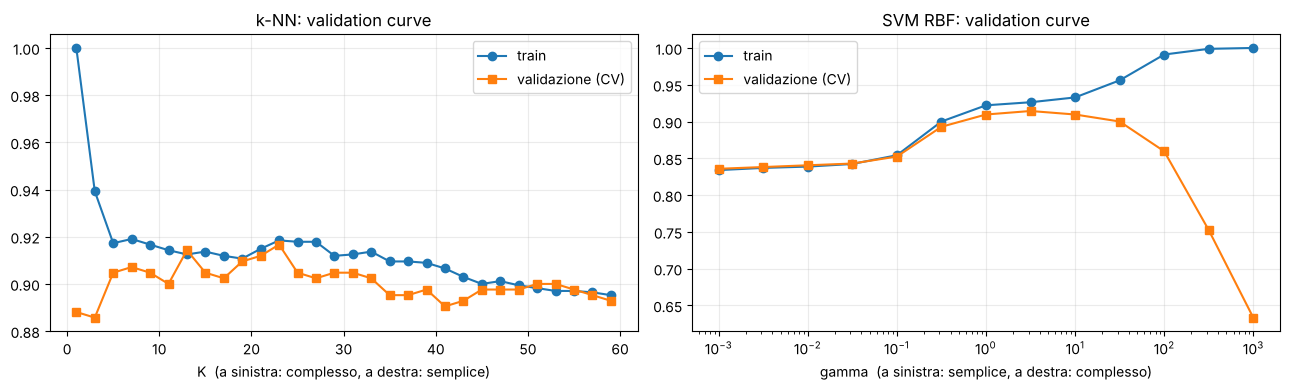

K migliore per k-NN: 23 | gamma migliore per SVM: 3.1622776601683795


In [34]:
Xm, ym = make_moons(600, noise=0.3, random_state=1)
Xmtr, Xmte, ymtr, ymte = train_test_split(Xm, ym, test_size=.3, stratify=ym, random_state=0)

ks = np.arange(1, 60, 2)
tr, va = validation_curve(make_pipeline(StandardScaler(), KNeighborsClassifier()), Xmtr, ymtr,
                          param_name="kneighborsclassifier__n_neighbors", param_range=ks, cv=5)
gs = np.logspace(-3, 3, 13)
tr2, va2 = validation_curve(make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1)), Xmtr, ymtr,
                            param_name="svc__gamma", param_range=gs, cv=5)

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
axs[0].plot(ks, tr.mean(1), "o-", label="train"); axs[0].plot(ks, va.mean(1), "s-", label="validazione (CV)")
axs[0].set_xlabel("K  (a sinistra: complesso, a destra: semplice)"); axs[0].set_title("k-NN: validation curve"); axs[0].legend()
axs[1].semilogx(gs, tr2.mean(1), "o-", label="train"); axs[1].semilogx(gs, va2.mean(1), "s-", label="validazione (CV)")
axs[1].set_xlabel("gamma  (a sinistra: semplice, a destra: complesso)"); axs[1].set_title("SVM RBF: validation curve"); axs[1].legend()
plt.tight_layout(); plt.show()
print("K migliore per k-NN:", int(ks[va.mean(1).argmax()]), "| gamma migliore per SVM:", float(gs[va2.mean(1).argmax()]))

**Cosa guardare.** In entrambi i grafici la curva di **train** sale con la complessità (a sinistra per K, a destra per gamma). Nella **SVM** la curva di validazione sale e poi **crolla**: il punto in cui si stacca dal train è l'overfitting. Nel **k-NN** l'effetto è molto più piccolo e rumoroso (differenze di 1-3 punti percentuali): con `K=1` il train è 1.00 ma la validazione è tra le più basse. Scegli la manopola dove la validazione è massima, **non** dove il train è massimo.

### Le tue parole (3)
Con un esempio a scelta (k-NN o SVM), spiega a un compagno **cosa vuol dire** che la validation curve "scende" mentre il train sale, e cosa faresti nel progetto.

### GridSearchCV e nested CV in codice (nb 06, slide *Nested cross-validation*, template)

- **GridSearchCV**: prova tutte le combinazioni della griglia, per ognuna fa una K-fold e tiene la migliore. Il nome dei parametri in pipeline è `nomestep__parametro`.
- **Attenzione**: il punteggio migliore trovato dalla GridSearch è **ottimista**, perché hai scelto proprio la combinazione che è andata meglio su quei fold (*selection bias*).
- **Nested CV**: una CV **esterna** valuta l'intera procedura "GridSearch + modello". Il punteggio esterno è una stima onesta. È quello che fa il template con `cross_val_score(GridSearchCV(...))` (o `RandomizedSearchCV`).

In [35]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
pipe = make_pipeline(StandardScaler(), SVC(kernel="rbf"))
griglia = {"svc__C": [0.1, 1, 10, 100], "svc__gamma": [0.01, 0.1, 1, 10]}
gs = GridSearchCV(pipe, griglia, cv=StratifiedKFold(5, shuffle=True, random_state=0), scoring="f1")
gs.fit(Xmtr, ymtr)
print("migliori parametri:", gs.best_params_, "| F1 interna (ottimista):", round(gs.best_score_, 3))
esterna = cross_val_score(gs, Xmtr, ymtr, cv=StratifiedKFold(5, shuffle=True, random_state=1), scoring="f1")
print("nested CV, F1 esterna:", esterna.round(3), "media", round(esterna.mean(), 3))
print("addestramenti: 16 combinazioni × 5 fold interni × 5 fold esterni = 400 (+ i refit)")

migliori parametri: {'svc__C': 1, 'svc__gamma': 1} | F1 interna (ottimista): 0.915


nested CV, F1 esterna: [0.875 0.932 0.916 0.92  0.876] media 0.904
addestramenti: 16 combinazioni × 5 fold interni × 5 fold esterni = 400 (+ i refit)


*(scrivi qui la tua risposta)*

# Parte E. Preprocessing: il primo passo di ogni progetto `[corso]` (nb 01)

Nel progetto viene **prima** di tutto il resto; la metto qui in fondo per non spezzare il ripasso dei modelli.

| Problema | Soluzione sklearn | Note |
|---|---|---|
| **Valori mancanti** | `SimpleImputer(strategy="mean" / "median" / "most_frequent")` | oppure eliminare righe o colonne; la mediana è robusta agli outlier |
| **Categoriche nominali** (es. città) | `OneHotEncoder` | una colonna 0/1 per categoria; `handle_unknown="ignore"` per categorie mai viste |
| **Categoriche ordinali** (es. S < M < L) | `OrdinalEncoder` con l'ordine giusto | 0, 1, 2 hanno senso solo se l'ordine esiste |
| **Discretizzazione** (binning) | `KBinsDiscretizer` | trasforma un numero in fasce; perde informazione |
| **Scale diverse** | `StandardScaler` (media 0, dev. std 1) o `MinMaxScaler` ([0, 1]) | indispensabile per k-NN, SVM, gradient descent, PCA |
| **Colonne di tipo diverso** | `ColumnTransformer` + `Pipeline` | ogni gruppo di colonne il suo trattamento |

**La regola d'oro**: ogni trasformazione si **allena solo sul training** (`fit`) e si **applica** al test (`transform`). Dentro una `Pipeline` succede da solo, anche dentro la cross-validation. Se imputi la media calcolata su **tutto** il dataset, informazioni del test entrano nel training: è **data leakage** (la domanda aperta sul template).

Il grafico sotto mostra perché lo scaling conta: il k-NN con feature non scalate dà retta quasi solo alla feature con i numeri più grandi.

PRIMA:


,eta,reddito,citta
0,22.0,18000.0,Pavia
1,NaN,32000.0,Milano
2,35.0,NaN,NaN
3,58.0,61000.0,Pavia
4,41.0,45000.0,Lodi


DOPO il ColumnTransformer:


,num__eta,num__reddito,cat__citta_Lodi,cat__citta_Milano,cat__citta_Pavia
0,-1.45,-1.47,0.0,0.0,1.0
1,-0.07,-0.49,0.0,1.0,0.0
2,-0.33,-0.03,0.0,0.0,1.0
3,1.66,1.55,0.0,0.0,1.0
4,0.19,0.43,1.0,0.0,0.0


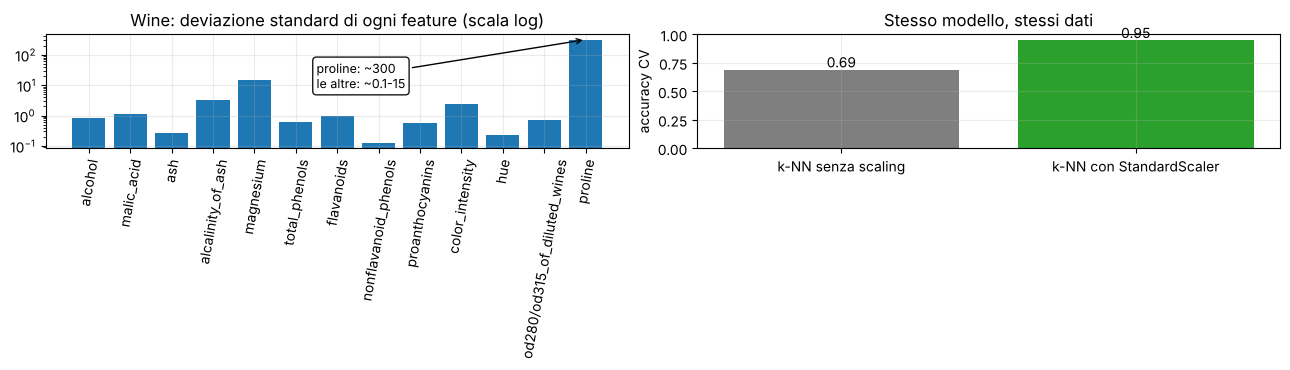

In [36]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
df = pd.DataFrame({"eta": [22, np.nan, 35, 58, 41], "reddito": [18000, 32000, np.nan, 61000, 45000],
                   "citta": ["Pavia", "Milano", np.nan, "Pavia", "Lodi"]})
prep = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), ["eta", "reddito"]),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("oh", OneHotEncoder(handle_unknown="ignore"))]), ["citta"]),
])
print("PRIMA:"); display(df)
print("DOPO il ColumnTransformer:")
display(pd.DataFrame(prep.fit_transform(df), columns=prep.get_feature_names_out()).round(2))

Xw2, yw2 = load_wine(return_X_y=True)
senza = cross_val_score(KNeighborsClassifier(5), Xw2, yw2, cv=5).mean()
con = cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(5)), Xw2, yw2, cv=5).mean()
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].bar(load_wine().feature_names, Xw2.std(0)); ax[0].set_yscale("log"); ax[0].tick_params(axis="x", rotation=80)
ax[0].set_title("Wine: deviazione standard di ogni feature (scala log)")
annota(ax[0], "proline: ~300\nle altre: ~0.1-15", (12, Xw2.std(0)[12]), (5.5, 8))
ax[1].bar(["k-NN senza scaling", "k-NN con StandardScaler"], [senza, con], color=["tab:gray", "tab:green"])
ax[1].set_ylim(0, 1); ax[1].set_ylabel("accuracy CV")
for i, v in enumerate([senza, con]): ax[1].text(i, v + .02, f"{v:.2f}", ha="center")
ax[1].set_title("Stesso modello, stessi dati")
plt.tight_layout(); plt.show()

# Mappa mentale finale

| Modello / tecnica | Tipo | Peculiarità (in una riga) | Forte | Debole | Manopola principale |
|---|---|---|---|---|---|
| Dummy | baseline | ignora le feature | metro minimo | non è un candidato | strategy |
| Perceptron | lineare | errore di soglia (0/1) | converge se separabile | oscilla altrimenti | eta0, max_iter |
| Adaline | lineare | errore quadratico su $z$ | costo liscio: GD o closed form | punisce i punti "troppo giusti" | $\eta$, epoche |
| Logistica | lineare | sigmoide e log-loss: probabilità | interpretabile, soglia regolabile | confine lineare | C |
| OvR / OvO / softmax | multiclasse | come estendere a $K$ classi | — | OvO: $K(K-1)/2$ modelli | — |
| Feature mapping | trucco | nuove colonne → confine curvo | semplice | colonne esplodono | grado |
| SVM lineare | lineare | margine massimo, support vector | scelta unica tra infinite rette | niente probabilità dirette | C |
| SVM RBF | non lineare (kernel) | somma di somiglianze con i support vector | flessibile, centri adattivi | lenta, sensibile | gamma, C |
| k-NN | non parametrico | niente training, vota i vicini | semplice, qualunque distanza | memoria, predizione lenta, soffre la dimensione | K, weights, metric |
| LDA (classif.) | lineare, generativo | nuvole gaussiane con stessa forma | formula chiusa, multiclasse | ipotesi gaussiana | — |
| Filter / wrapper / LASSO | selezione | tiene **alcune colonne originali** | interpretabile | wrapper costoso | k, m, $\lambda$ |
| PCA | estrazione, non sup. | direzioni di massima varianza | veloce, scelta per varianza | può buttare ciò che separa | n_components |
| Kernel PCA | estrazione, non sup. | PCA con kernel | strutture curve | $N\times N$, $O(N^3)$ | kernel, gamma |
| LDA (riduzione) | estrazione, **sup.** | massimizza il Fisher score | poche componenti utili | al più $C-1$ componenti | n_components |
| OLS / Ridge / LASSO | regressione | minimi quadrati (+ L2 / L1) | semplici; L1 seleziona | lineari nei pesi | alpha |
| k-NN regression | regressione | media dei vicini | curve qualunque | come k-NN | K |

**Tre domande per orientarti** `[mio]`:
1. Il confine deve essere **retta o curva**? (lineare contro kernel / k-NN / feature mapping)
2. Mi servono le **probabilità**? (logistica, LDA)
3. Quanti **campioni** e quante **dimensioni** ho? (k-NN e SVM RBF soffrono con tanti campioni o dimensioni; selezione ed estrazione aiutano)

E sempre: **decide la cross-validation**, non l'occhio.

# Cosa manca ancora (programma del corso, non ancora nei notebook)

**Decision Tree**, **ensemble** (bagging, Random Forest, boosting/XGBoost), **clustering** (k-means, gerarchico, density-based). La **Random Forest** serve anche per il template. Il **sampler** del template (`imbalanced-learn`) non è in nessun notebook: va chiesto o studiato a parte.

# Spazio libero per i tuoi appunti

*(scrivi qui)*